## Results Analysis

Analysis of full LOSO run results.
106 subjects, both stopping criteria: kappa and composite.

Covers:
- Per subject breakdown and distribution of kappa
- Stopping criteria comparison
- Flagged subject analysis (S086, S090)
- Baseline comparison (after baseline run)

In [49]:
import pandas as pd
import numpy as np
import json
from pathlib import Path
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.signal import welch
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import cross_val_score

### Config

In [50]:
# paths
results_path = Path("../results")
figures_path = Path("../results/figures")
processed_path = Path("../Data/processed")


figures_path.mkdir(exist_ok=True)

In [51]:
def extract_band_power_features(raw_data, fs=160):
    """
    extracts mu and beta band power per channel per trial
    mu band: 8 to 13 Hz
    beta band: 13 to 30 Hz
    """
    n_trials, n_channels, n_timepoints = raw_data.shape

    # output: n_trials x (n_channels * 2 bands)
    features = np.zeros((n_trials, n_channels * 2))

    for trial_idx in range(n_trials):
        for ch_idx in range(n_channels):
            signal = raw_data[trial_idx, ch_idx, :]

            # compute power spectral density using Welch method
            freqs, psd = welch(signal, fs=fs, nperseg=min(256, n_timepoints))

            # mu band power: 8 to 13 Hz
            mu_mask = (freqs >= 8) & (freqs <= 13)
            mu_power = np.mean(psd[mu_mask])

            # beta band power: 13 to 30 Hz
            beta_mask = (freqs > 13) & (freqs <= 30)
            beta_power = np.mean(psd[beta_mask])

            # store: first n_channels are mu, next n_channels are beta
            features[trial_idx, ch_idx] = mu_power
            features[trial_idx, n_channels + ch_idx] = beta_power

    return features

In [52]:
# 106 subjects after removing S088, S092, S100 (incompatible sampling rate)
excluded = ['S088', 'S092', 'S100']

valid_subjects = []
for i in range(1, 110):
    subject_id = f'S{str(i).zfill(3)}'
    subject_file = processed_path / f'{subject_id}_processed.npz'
    if subject_file.exists() and subject_id not in excluded:
        valid_subjects.append(subject_id)

print(f"Valid subjects: {len(valid_subjects)}")
print(f"First five: {valid_subjects[:5]}")
print(f"Last five: {valid_subjects[-5:]}")

Valid subjects: 106
First five: ['S001', 'S002', 'S003', 'S004', 'S005']
Last five: ['S105', 'S106', 'S107', 'S108', 'S109']


### Analysis

In [53]:
# load summary csv
summary = pd.read_csv(results_path / 'loso_summary_no_warmup.csv')

# load full json results
with open(results_path / 'loso_results_no_warmup.json', 'r') as f:
    full_results = json.load(f)

print(f"Summary loaded: {summary.shape[0]} subjects, {summary.shape[1]} columns")
print(f"Full results loaded: {len(full_results)} subjects")

Summary loaded: 106 subjects, 23 columns
Full results loaded: 106 subjects


In [54]:
# basic statistics summary
print("Kappa stopping criterion:")
print(f"  Mean kappa:   {summary['kappa_kappa'].mean():.4f}")
print(f"  Median kappa: {summary['kappa_kappa'].median():.4f}")
print(f"  Std kappa:    {summary['kappa_kappa'].std():.4f}")
print(f"  Min kappa:    {summary['kappa_kappa'].min():.4f}")
print(f"  Max kappa:    {summary['kappa_kappa'].max():.4f}")

print()
print("Composite stopping criterion:")
print(f"  Mean kappa:   {summary['composite_kappa'].mean():.4f}")
print(f"  Median kappa: {summary['composite_kappa'].median():.4f}")
print(f"  Std kappa:    {summary['composite_kappa'].std():.4f}")
print(f"  Min kappa:    {summary['composite_kappa'].min():.4f}")
print(f"  Max kappa:    {summary['composite_kappa'].max():.4f}")

print()
print("Kappa stopping accuracy:")
print(f"  Mean:   {summary['kappa_accuracy'].mean():.4f}")
print(f"  Median: {summary['kappa_accuracy'].median():.4f}")
print(f"  Std:    {summary['kappa_accuracy'].std():.4f}")

print()
# subjects above chance (kappa > 0.1)
above_chance_kappa = (summary['kappa_kappa'] > 0.1).sum()
above_chance_composite = (summary['composite_kappa'] > 0.1).sum()
print(f"Subjects above chance (kappa > 0.1):")
print(f"  Kappa stopping:     {above_chance_kappa}/106 ({above_chance_kappa/106*100:.1f}%)")
print(f"  Composite stopping: {above_chance_composite}/106 ({above_chance_composite/106*100:.1f}%)")

Kappa stopping criterion:
  Mean kappa:   0.4918
  Median kappa: 0.4858
  Std kappa:    0.2426
  Min kappa:    -0.0630
  Max kappa:    0.9556

Composite stopping criterion:
  Mean kappa:   0.5039
  Median kappa: 0.5000
  Std kappa:    0.2497
  Min kappa:    -0.1023
  Max kappa:    1.0000

Kappa stopping accuracy:
  Mean:   0.7454
  Median: 0.7417
  Std:    0.1223

Subjects above chance (kappa > 0.1):
  Kappa stopping:     102/106 (96.2%)
  Composite stopping: 101/106 (95.3%)


In [55]:
# per subject breakdown sorted by kappa stopping performance
subject_comparison = summary[['subject_id',
                               'kappa_kappa',
                               'composite_kappa',
                               'kappa_accuracy',
                               'kappa_adaptation_quality',
                               'composite_adaptation_quality']].copy()

# add difference column
subject_comparison['kappa_diff'] = (subject_comparison['kappa_kappa'] -
                                    subject_comparison['composite_kappa'])

# sort by kappa stopping performance
subject_comparison = subject_comparison.sort_values('kappa_kappa', ascending=False)

print("Top 10 subjects (kappa stopping):")
print(subject_comparison.head(10).to_string(index=False))
print()
print("Bottom 10 subjects (kappa stopping):")
print(subject_comparison.tail(10).to_string(index=False))
print()
print("Subjects where composite beats kappa by more than 0.1:")
composite_better = subject_comparison[subject_comparison['kappa_diff'] < -0.1]
print(composite_better[['subject_id', 'kappa_kappa', 'composite_kappa', 'kappa_diff']].to_string(index=False))
print()
print("Subjects where kappa beats composite by more than 0.1:")
kappa_better = subject_comparison[subject_comparison['kappa_diff'] > 0.1]
print(kappa_better[['subject_id', 'kappa_kappa', 'composite_kappa', 'kappa_diff']].to_string(index=False))

Top 10 subjects (kappa stopping):
subject_id  kappa_kappa  composite_kappa  kappa_accuracy  kappa_adaptation_quality  composite_adaptation_quality  kappa_diff
      S029     0.955577         1.000000        0.977778                  1.125549                      1.099605   -0.044423
      S007     0.955490         0.955490        0.977778                  1.082660                      1.108243    0.000000
      S085     0.952164         1.000000        0.976190                  1.115814                      1.074713   -0.047836
      S015     0.911243         0.822835        0.955556                  1.110160                      1.060092    0.088408
      S055     0.910891         0.911067        0.955556                  1.043931                      1.085361   -0.000176
      S034     0.867257         0.867257        0.933333                  1.174668                      1.102401    0.000000
      S062     0.866204         0.866469        0.933333                  1.110795         

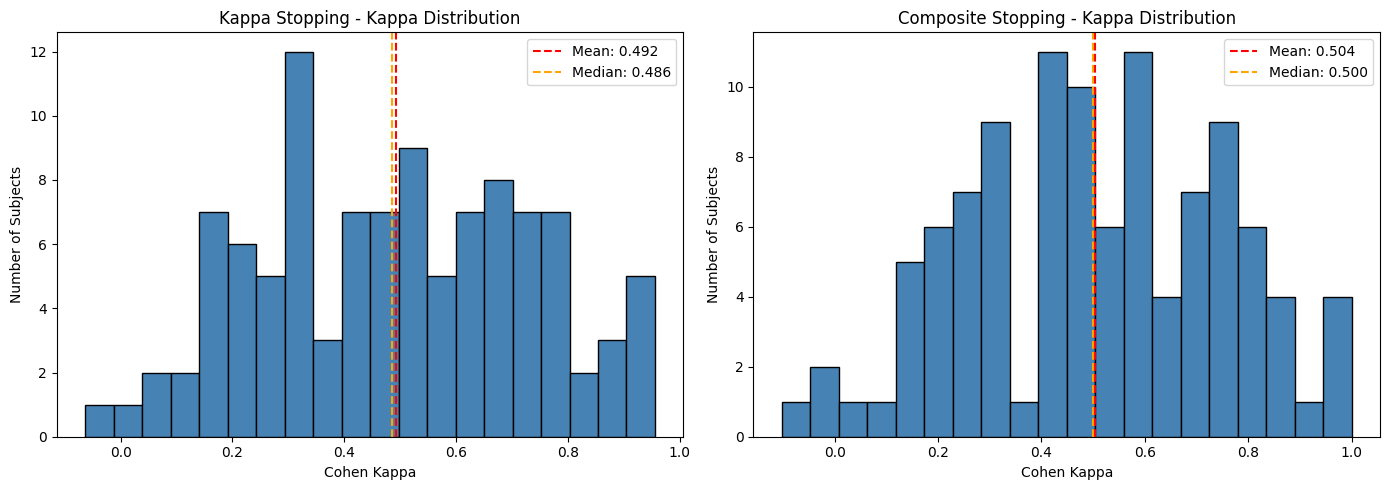

Figure saved


In [56]:
# distribution of kappa across subjects
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# kappa stopping distribution
axes[0].hist(summary['kappa_kappa'], bins=20, edgecolor='black', color='steelblue')
axes[0].axvline(summary['kappa_kappa'].mean(), color='red',
                linestyle='--', label=f"Mean: {summary['kappa_kappa'].mean():.3f}")
axes[0].axvline(summary['kappa_kappa'].median(), color='orange',
                linestyle='--', label=f"Median: {summary['kappa_kappa'].median():.3f}")
axes[0].set_title('Kappa Stopping - Kappa Distribution')
axes[0].set_xlabel('Cohen Kappa')
axes[0].set_ylabel('Number of Subjects')
axes[0].legend()

# composite stopping distribution
axes[1].hist(summary['composite_kappa'], bins=20, edgecolor='black', color='steelblue')
axes[1].axvline(summary['composite_kappa'].mean(), color='red',
                linestyle='--', label=f"Mean: {summary['composite_kappa'].mean():.3f}")
axes[1].axvline(summary['composite_kappa'].median(), color='orange',
                linestyle='--', label=f"Median: {summary['composite_kappa'].median():.3f}")
axes[1].set_title('Composite Stopping - Kappa Distribution')
axes[1].set_xlabel('Cohen Kappa')
axes[1].set_ylabel('Number of Subjects')
axes[1].legend()

plt.tight_layout()
plt.savefig(figures_path / 'kappa_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Figure saved")

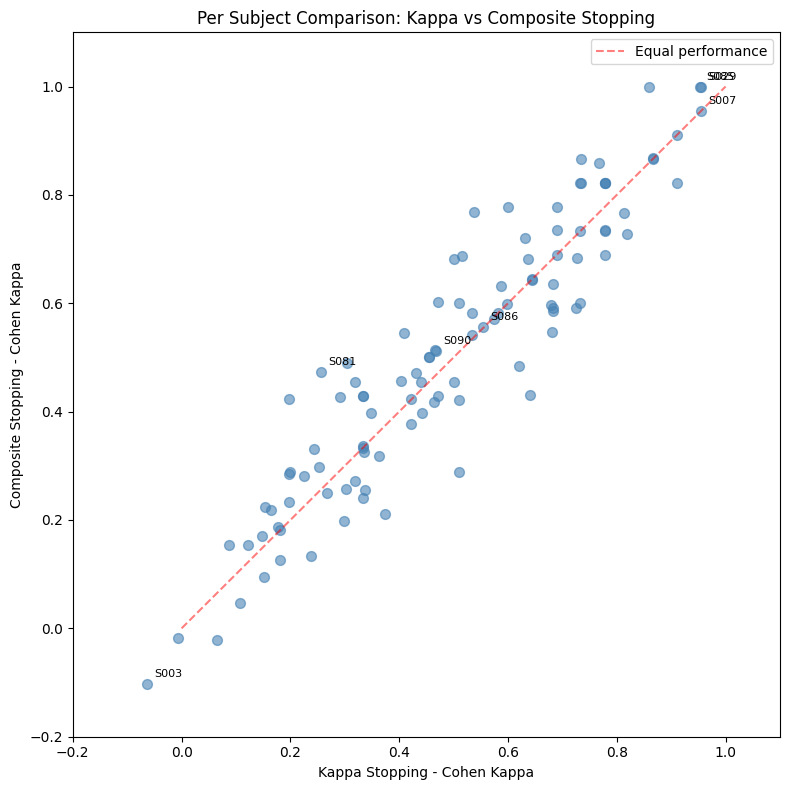

Figure saved


In [57]:
# scatter plot: kappa stopping vs composite stopping per subject
fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(summary['kappa_kappa'], summary['composite_kappa'],
           alpha=0.6, s=50, color='steelblue')

# diagonal line: equal performance
ax.plot([0, 1], [0, 1], 'r--', alpha=0.5, label='Equal performance')

# label flagged subjects
for subject in ['S086', 'S090', 'S003', 'S081', 'S007', 'S029', 'S085']:
    row = summary[summary['subject_id'] == subject]
    if len(row) > 0:
        ax.annotate(subject,
                   (row['kappa_kappa'].values[0], row['composite_kappa'].values[0]),
                   textcoords="offset points", xytext=(5, 5), fontsize=8)

ax.set_xlabel('Kappa Stopping - Cohen Kappa')
ax.set_ylabel('Composite Stopping - Cohen Kappa')
ax.set_title('Per Subject Comparison: Kappa vs Composite Stopping')
ax.legend()
ax.set_xlim(-0.2, 1.1)
ax.set_ylim(-0.2, 1.1)

plt.tight_layout()
plt.savefig(figures_path / 'stopping_criteria_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Figure saved")

In [58]:
# S086 and S090 specific analysis against average
print("Average subject performance (all 106 subjects):")
print(f"  Mean kappa (kappa stopping):     {summary['kappa_kappa'].mean():.4f}")
print(f"  Mean kappa (composite stopping): {summary['composite_kappa'].mean():.4f}")
print(f"  Mean accuracy (kappa stopping):  {summary['kappa_accuracy'].mean():.4f}")
print()

# S086 analysis
s086 = summary[summary['subject_id'] == 'S086'].iloc[0]
print("S086 (flagged: residual artifact):")
print(f"  Kappa stopping kappa:      {s086['kappa_kappa']:.4f}")
print(f"  Composite stopping kappa:  {s086['composite_kappa']:.4f}")
print(f"  Kappa stopping accuracy:   {s086['kappa_accuracy']:.4f}")
print(f"  Kappa vs average:          {s086['kappa_kappa'] - summary['kappa_kappa'].mean():+.4f}")
print(f"  Adaptation quality kappa:  {s086['kappa_adaptation_quality']:.4f}")
print(f"  Adaptation quality comp:   {s086['composite_adaptation_quality']:.4f}")
print()

# S090 analysis
s090 = summary[summary['subject_id'] == 'S090'].iloc[0]
print("S090 (flagged: atypical lateralisation):")
print(f"  Kappa stopping kappa:      {s090['kappa_kappa']:.4f}")
print(f"  Composite stopping kappa:  {s090['composite_kappa']:.4f}")
print(f"  Kappa stopping accuracy:   {s090['kappa_accuracy']:.4f}")
print(f"  Kappa vs average:          {s090['kappa_kappa'] - summary['kappa_kappa'].mean():+.4f}")
print(f"  Adaptation quality kappa:  {s090['kappa_adaptation_quality']:.4f}")
print(f"  Adaptation quality comp:   {s090['composite_adaptation_quality']:.4f}")
print()

# percentile rank of both flagged subjects
s086_percentile = (summary['kappa_kappa'] < s086['kappa_kappa']).mean() * 100
s090_percentile = (summary['kappa_kappa'] < s090['kappa_kappa']).mean() * 100

print(f"S086 percentile rank: {s086_percentile:.1f}th percentile")
print(f"S090 percentile rank: {s090_percentile:.1f}th percentile")
print(f"(50th percentile = average subject)")

Average subject performance (all 106 subjects):
  Mean kappa (kappa stopping):     0.4918
  Mean kappa (composite stopping): 0.5039
  Mean accuracy (kappa stopping):  0.7454

S086 (flagged: residual artifact):
  Kappa stopping kappa:      0.5545
  Composite stopping kappa:  0.5562
  Kappa stopping accuracy:   0.7778
  Kappa vs average:          +0.0627
  Adaptation quality kappa:  1.0817
  Adaptation quality comp:   1.1414

S090 (flagged: atypical lateralisation):
  Kappa stopping kappa:      0.4675
  Composite stopping kappa:  0.5123
  Kappa stopping accuracy:   0.7333
  Kappa vs average:          -0.0243
  Adaptation quality kappa:  1.0878
  Adaptation quality comp:   1.0834

S086 percentile rank: 58.5th percentile
S090 percentile rank: 47.2th percentile
(50th percentile = average subject)


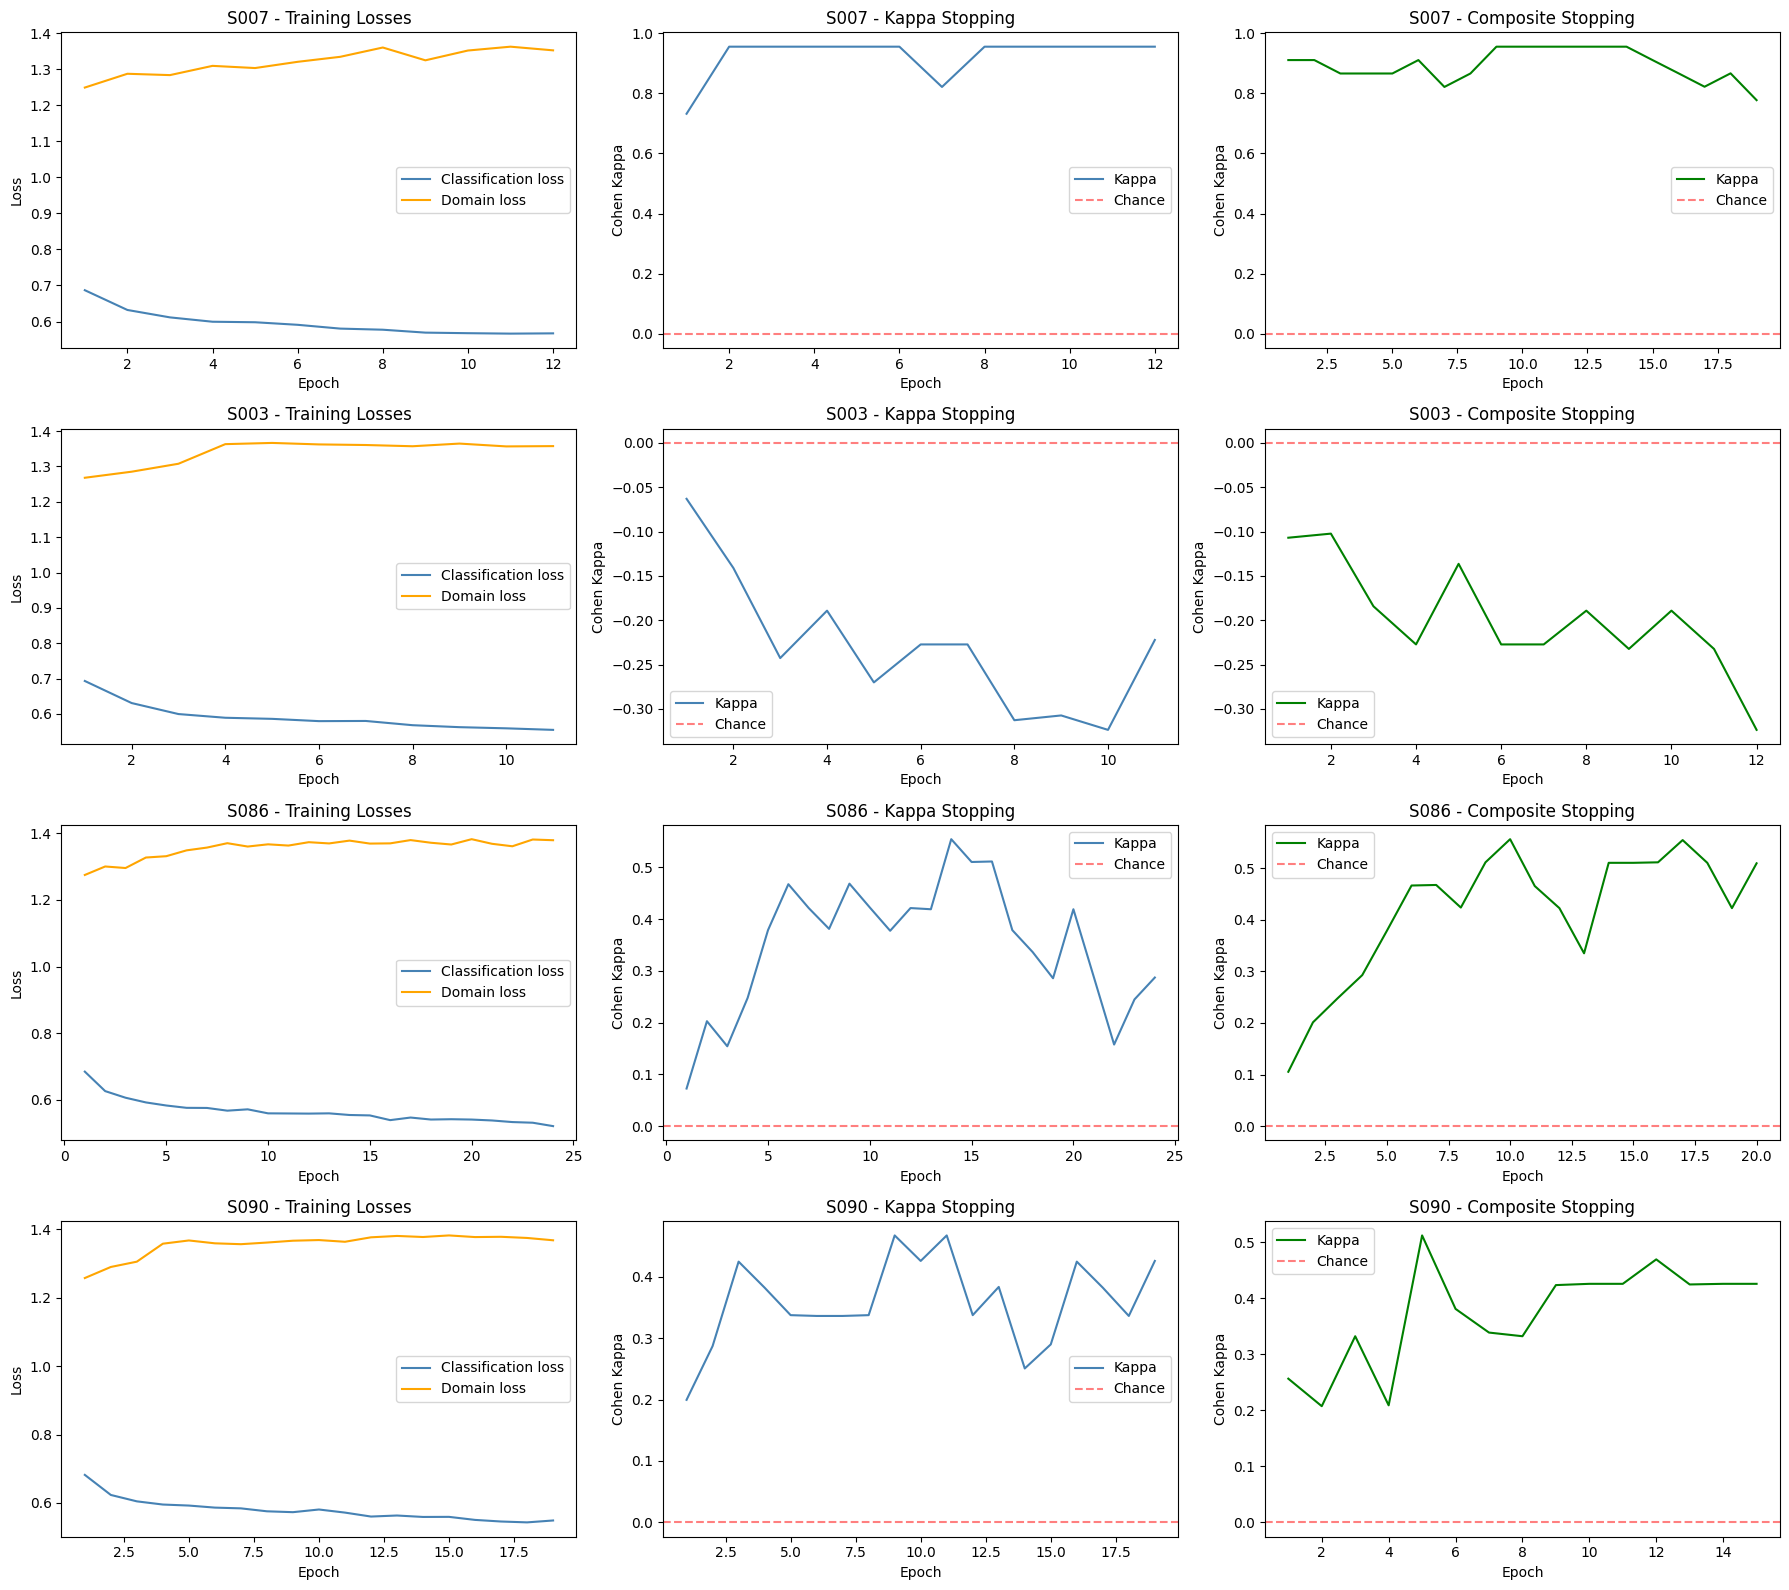

Figure saved


In [59]:
# training curves: classification loss, domain loss, kappa comparison
# four subjects: S007 (best), S003 (negative transfer), S086 (artifact), S090 (atypical)

fig, axes = plt.subplots(4, 3, figsize=(18, 16))

for idx, subject_id in enumerate(['S007', 'S003', 'S086', 'S090']):
    kappa_data = full_results[subject_id]['kappa_stopping']['log']
    composite_data = full_results[subject_id]['composite_stopping']['log']

    # panel 1: losses (kappa stopping only, representative)
    axes[idx, 0].plot(kappa_data['epoch'], kappa_data['class_loss'],
                      label='Classification loss', color='steelblue')
    axes[idx, 0].plot(kappa_data['epoch'], kappa_data['domain_loss'],
                      label='Domain loss', color='orange')
    axes[idx, 0].set_title(f'{subject_id} - Training Losses')
    axes[idx, 0].set_xlabel('Epoch')
    axes[idx, 0].set_ylabel('Loss')
    axes[idx, 0].legend()

    # panel 2: kappa stopping kappa
    axes[idx, 1].plot(kappa_data['epoch'], kappa_data['kappa'],
                      label='Kappa', color='steelblue')
    axes[idx, 1].axhline(y=0, color='red', linestyle='--',
                          alpha=0.5, label='Chance')
    axes[idx, 1].set_title(f'{subject_id} - Kappa Stopping')
    axes[idx, 1].set_xlabel('Epoch')
    axes[idx, 1].set_ylabel('Cohen Kappa')
    axes[idx, 1].legend()

    # panel 3: composite stopping kappa
    axes[idx, 2].plot(composite_data['epoch'], composite_data['kappa'],
                      label='Kappa', color='green')
    axes[idx, 2].axhline(y=0, color='red', linestyle='--',
                          alpha=0.5, label='Chance')
    axes[idx, 2].set_title(f'{subject_id} - Composite Stopping')
    axes[idx, 2].set_xlabel('Epoch')
    axes[idx, 2].set_ylabel('Cohen Kappa')
    axes[idx, 2].legend()

plt.tight_layout()
plt.savefig(figures_path / 'training_curves_combined.png',
            dpi=150, bbox_inches='tight')
plt.show()
print(f"Figure saved")

In [60]:
# point 8: adaptation quality correlation with kappa
import scipy.stats as stats

# kappa stopping
corr_kappa, pval_kappa = stats.pearsonr(
    summary['kappa_adaptation_quality'],
    summary['kappa_kappa']
)

# composite stopping
corr_composite, pval_composite = stats.pearsonr(
    summary['composite_adaptation_quality'],
    summary['composite_kappa']
)

print("Adaptation quality vs kappa correlation:")
print(f"  Kappa stopping:     r = {corr_kappa:.4f}, p = {pval_kappa:.4f}")
print(f"  Composite stopping: r = {corr_composite:.4f}, p = {pval_composite:.4f}")
print()

if pval_kappa < 0.05:
    print("Kappa stopping: significant correlation")
else:
    print("Kappa stopping: no significant correlation")

if pval_composite < 0.05:
    print("Composite stopping: significant correlation")
else:
    print("Composite stopping: no significant correlation")

Adaptation quality vs kappa correlation:
  Kappa stopping:     r = 0.1365, p = 0.1628
  Composite stopping: r = -0.0283, p = 0.7733

Kappa stopping: no significant correlation
Composite stopping: no significant correlation


In [61]:
# check pre-adaptation MMD vs final kappa
corr_mmd, pval_mmd = stats.pearsonr(
    summary['kappa_pre_mmd_multiscale'],
    summary['kappa_kappa']
)

corr_riem, pval_riem = stats.pearsonr(
    summary['kappa_pre_riemannian'],
    summary['kappa_kappa']
)

print("Pre-adaptation distribution distance vs kappa:")
print(f"  MMD multiscale: r = {corr_mmd:.4f}, p = {pval_mmd:.4f}")
print(f"  Riemannian:     r = {corr_riem:.4f}, p = {pval_riem:.4f}")

Pre-adaptation distribution distance vs kappa:
  MMD multiscale: r = -0.0990, p = 0.3126
  Riemannian:     r = -0.0678, p = 0.4899


In [62]:
# negative transfer investigation
# S003, S018, S036 consistently at the bottom

negative_transfer_subjects = ['S003', 'S018', 'S036']
all_subjects_mean_kappa = summary['kappa_kappa'].mean()

print("Negative transfer subject analysis:")
print(f"Dataset mean kappa: {all_subjects_mean_kappa:.4f}")
print()

for subject_id in negative_transfer_subjects:
    row = summary[summary['subject_id'] == subject_id].iloc[0]
    subject_log = full_results[subject_id]['kappa_stopping']['log']

    print(f"{subject_id}:")
    print(f"  Kappa stopping kappa:      {row['kappa_kappa']:.4f}")
    print(f"  Composite stopping kappa:  {row['composite_kappa']:.4f}")
    print(f"  Kappa vs mean:             {row['kappa_kappa'] - all_subjects_mean_kappa:+.4f}")
    print(f"  Accuracy:                  {row['kappa_accuracy']:.4f}")
    print(f"  Adaptation quality:        {row['kappa_adaptation_quality']:.4f}")
    print(f"  Pre MMD multiscale:        {row['kappa_pre_mmd_multiscale']:.6f}")
    print(f"  Pre Riemannian:            {row['kappa_pre_riemannian']:.6f}")
    print(f"  Epochs run:                {row['kappa_total_epochs']}")
    print(f"  Best epoch:                {row['kappa_best_epoch']}")
    print(f"  Early stopping triggered:  {row['kappa_early_stopping']}")

    # check if kappa was ever positive during training
    kappa_values = subject_log['kappa']
    max_kappa_during_training = max(kappa_values)
    positive_epochs = sum(1 for k in kappa_values if k > 0.1)

    print(f"  Max kappa during training: {max_kappa_during_training:.4f}")
    print(f"  Epochs with kappa > 0.1:   {positive_epochs}/{len(kappa_values)}")
    print()

Negative transfer subject analysis:
Dataset mean kappa: 0.4918

S003:
  Kappa stopping kappa:      -0.0630
  Composite stopping kappa:  -0.1023
  Kappa vs mean:             -0.5548
  Accuracy:                  0.4773
  Adaptation quality:        1.0706
  Pre MMD multiscale:        0.194765
  Pre Riemannian:            0.853765
  Epochs run:                11
  Best epoch:                1
  Early stopping triggered:  True
  Max kappa during training: -0.0630
  Epochs with kappa > 0.1:   0/11

S018:
  Kappa stopping kappa:      -0.0058
  Composite stopping kappa:  -0.0177
  Kappa vs mean:             -0.4976
  Accuracy:                  0.4889
  Adaptation quality:        1.0650
  Pre MMD multiscale:        0.337614
  Pre Riemannian:            1.742452
  Epochs run:                11
  Best epoch:                1
  Early stopping triggered:  True
  Max kappa during training: -0.0058
  Epochs with kappa > 0.1:   0/11

S036:
  Kappa stopping kappa:      0.0653
  Composite stopping kappa

In [63]:
# corrected label check for negative transfer subjects
for subject_id in ['S003', 'S018', 'S036']:
    data = np.load(processed_path / f'{subject_id}_processed.npz')
    labels = data['labels']

    print(f"{subject_id}:")
    print(f"  Total trials: {len(labels)}")
    print(f"  T1 (label 2, left fist):  {(labels == 2).sum()}")
    print(f"  T2 (label 3, right fist): {(labels == 3).sum()}")
    print(f"  Balanced: {abs((labels==2).sum() - (labels==3).sum()) <= 2}")
    print()

S003:
  Total trials: 44
  T1 (label 2, left fist):  23
  T2 (label 3, right fist): 21
  Balanced: True

S018:
  Total trials: 45
  T1 (label 2, left fist):  22
  T2 (label 3, right fist): 23
  Balanced: True

S036:
  Total trials: 45
  T1 (label 2, left fist):  23
  T2 (label 3, right fist): 22
  Balanced: True



In [64]:
# check actual label values for negative transfer subjects


for subject_id in ['S003', 'S018', 'S036']:
    data = np.load(processed_path / f'{subject_id}_processed.npz')
    labels = data['labels']

    print(f"{subject_id}:")
    print(f"  Total trials: {len(labels)}")
    print(f"  Unique label values: {np.unique(labels)}")
    print(f"  Label counts: {np.bincount(labels.astype(int))}")
    print(f"  First 10 labels: {labels[:10]}")
    print()

S003:
  Total trials: 44
  Unique label values: [2 3]
  Label counts: [ 0  0 23 21]
  First 10 labels: [3 2 3 2 3 2 2 3 2 3]

S018:
  Total trials: 45
  Unique label values: [2 3]
  Label counts: [ 0  0 22 23]
  First 10 labels: [3 2 2 3 2 3 3 2 2 3]

S036:
  Total trials: 45
  Unique label values: [2 3]
  Label counts: [ 0  0 23 22]
  First 10 labels: [3 2 3 2 2 3 3 2 2 3]



### No base line:

## Results Context

The DANN results in `summary` (loaded from loso_results.json) are from the 
no-warmup run: min_epochs=0, warmup_epochs=0, alpha steepness 5, 
discriminator lr 10x, cycle target loader fix applied.

The baseline results in `baseline_df` use the same architecture with 
lambda_domain=0.0, min_epochs=0, warmup_epochs=0.
Both ran without warmup constraints.

A second DANN run with min_epochs=20 and warmup_epochs=10 is currently 
running. Results will be loaded separately as `summary_warmup` for 
three-way comparison: no-warmup DANN vs warmup DANN vs baseline.

Key finding from this comparison:
- No-warmup DANN mean kappa 0.4918 vs baseline 0.4996
- Baseline slightly outperforms no-warmup DANN overall
- Composite stopping strongest at higher thresholds (0.4: 71/106 vs 67/106)
- Adversarial training needs further optimisation to clearly outperform baseline

In [65]:
# load baseline results and compare with DANN
import json

with open(results_path / 'loso_results_baseline.json', 'r') as f:
    baseline_results = json.load(f)

# build baseline summary
baseline_kappas = []
for subject_id in valid_subjects:
    if subject_id in baseline_results and baseline_results[subject_id]:
        baseline_kappas.append({
            'subject_id': subject_id,
            'baseline_kappa': baseline_results[subject_id]['final_kappa'],
            'baseline_accuracy': baseline_results[subject_id]['final_accuracy']
        })

baseline_df = pd.DataFrame(baseline_kappas)

# merge with DANN results
comparison = summary[['subject_id', 'kappa_kappa', 'composite_kappa']].merge(
    baseline_df, on='subject_id'
)

comparison['dann_improvement'] = comparison['kappa_kappa'] - comparison['baseline_kappa']

print("No Adaptation Baseline vs DANN:")
print(f"\nBaseline (no adaptation):")
print(f"  Mean kappa:   {comparison['baseline_kappa'].mean():.4f}")
print(f"  Median kappa: {comparison['baseline_kappa'].median():.4f}")
print(f"  Std kappa:    {comparison['baseline_kappa'].std():.4f}")

print(f"\nDANN (kappa stopping):")
print(f"  Mean kappa:   {comparison['kappa_kappa'].mean():.4f}")
print(f"  Median kappa: {comparison['kappa_kappa'].median():.4f}")
print(f"  Std kappa:    {comparison['kappa_kappa'].std():.4f}")

print(f"\nDANN improvement over baseline:")
print(f"  Mean improvement:   {comparison['dann_improvement'].mean():+.4f}")
print(f"  Median improvement: {comparison['dann_improvement'].median():+.4f}")
print(f"  Subjects improved:  {(comparison['dann_improvement'] > 0).sum()}/106")
print(f"  Subjects worsened:  {(comparison['dann_improvement'] < 0).sum()}/106")
print(f"  Subjects unchanged: {(comparison['dann_improvement'] == 0).sum()}/106")

print(f"\nAbove chance (kappa > 0.1):")
above_baseline = (comparison['baseline_kappa'] > 0.1).sum()
above_dann = (comparison['kappa_kappa'] > 0.1).sum()
print(f"  Baseline: {above_baseline}/106")
print(f"  DANN:     {above_dann}/106")

No Adaptation Baseline vs DANN:

Baseline (no adaptation):
  Mean kappa:   0.4996
  Median kappa: 0.5109
  Std kappa:    0.2407

DANN (kappa stopping):
  Mean kappa:   0.4918
  Median kappa: 0.4858
  Std kappa:    0.2426

DANN improvement over baseline:
  Mean improvement:   -0.0078
  Median improvement: -0.0011
  Subjects improved:  41/106
  Subjects worsened:  59/106
  Subjects unchanged: 6/106

Above chance (kappa > 0.1):
  Baseline: 102/106
  DANN:     102/106


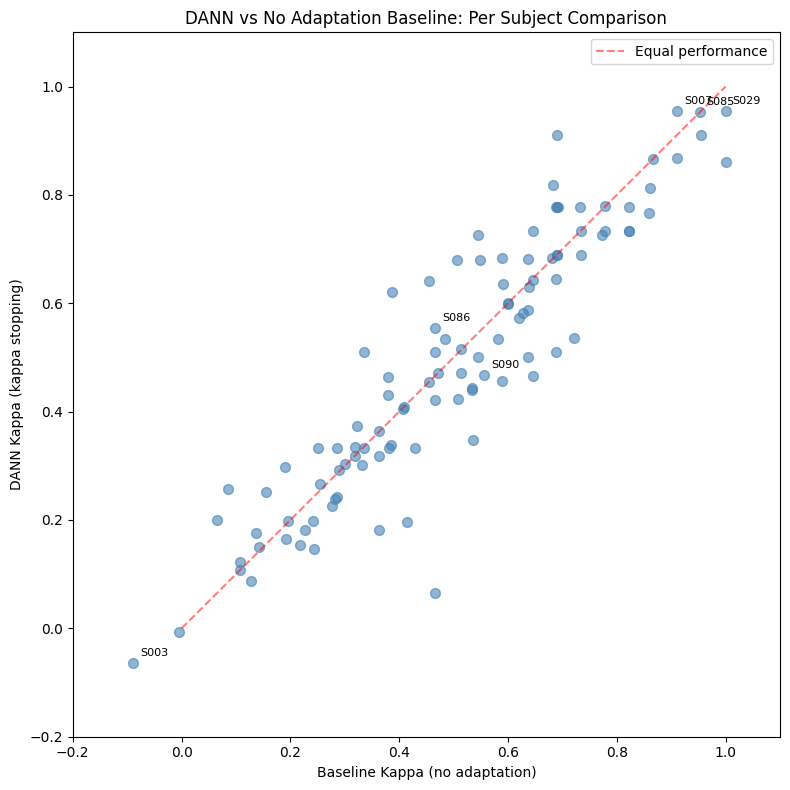

Figure saved


In [66]:
# scatter plot: baseline vs DANN per subject
fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(comparison['baseline_kappa'], comparison['kappa_kappa'],
           alpha=0.6, s=50, color='steelblue')

ax.plot([0, 1], [0, 1], 'r--', alpha=0.5, label='Equal performance')

for subject in ['S003', 'S007', 'S029', 'S085', 'S086', 'S090']:
    row = comparison[comparison['subject_id'] == subject]
    if len(row) > 0:
        ax.annotate(subject,
                   (row['baseline_kappa'].values[0],
                    row['kappa_kappa'].values[0]),
                   textcoords="offset points", xytext=(5, 5), fontsize=8)

ax.set_xlabel('Baseline Kappa (no adaptation)')
ax.set_ylabel('DANN Kappa (kappa stopping)')
ax.set_title('DANN vs No Adaptation Baseline: Per Subject Comparison')
ax.legend()
ax.set_xlim(-0.2, 1.1)
ax.set_ylim(-0.2, 1.1)

plt.tight_layout()
plt.savefig(figures_path / 'dann_vs_baseline.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Figure saved")

In [67]:
# kappa threshold analysis
# checking how many subjects are above chance at different thresholds
# addresses professor's question about threshold sensitivity

thresholds = [0.0, 0.1, 0.2, 0.3, 0.4]

print("Subjects above different kappa thresholds:")
print(f"{'Threshold':<12} {'Kappa stopping':<18} {'Composite stopping':<20} {'Baseline':<12}")
print("-" * 62)

for t in thresholds:
    k_above = (summary['kappa_kappa'] > t).sum()
    c_above = (summary['composite_kappa'] > t).sum()
    b_above = (baseline_df['baseline_kappa'] > t).sum()
    print(f"{t:<12} {k_above}/106{'':<10} {c_above}/106{'':<12} {b_above}/106")

Subjects above different kappa thresholds:
Threshold    Kappa stopping     Composite stopping   Baseline    
--------------------------------------------------------------
0.0          104/106           103/106             104/106
0.1          102/106           101/106             102/106
0.2          89/106           93/106             93/106
0.3          81/106           79/106             81/106
0.4          67/106           71/106             67/106


In [68]:
thresholds = [0.0, 0.1, 0.2, 0.3, 0.4]

print("Subjects above different kappa thresholds:")
print(f"{'Threshold':<12} {'Kappa stopping':<20} {'Composite stopping':<20}")
print("-" * 52)

for t in thresholds:
    k_above = (summary['kappa_kappa'] > t).sum()
    c_above = (summary['composite_kappa'] > t).sum()
    print(f"{t:<12} {k_above}/106{'':<12} {c_above}/106")

Subjects above different kappa thresholds:
Threshold    Kappa stopping       Composite stopping  
----------------------------------------------------
0.0          104/106             103/106
0.1          102/106             101/106
0.2          89/106             93/106
0.3          81/106             79/106
0.4          67/106             71/106


In [69]:
# reload baseline results with correct 106 subjects
with open(results_path / 'loso_results_baseline.json', 'r') as f:
    baseline_results = json.load(f)

print(f"Baseline subjects loaded: {len(baseline_results)}")

# rebuild baseline_df
baseline_kappas = []
for subject_id in valid_subjects:
    if subject_id in baseline_results and baseline_results[subject_id]:
        baseline_kappas.append({
            'subject_id': subject_id,
            'baseline_kappa': baseline_results[subject_id]['final_kappa'],
            'baseline_accuracy': baseline_results[subject_id]['final_accuracy']
        })

baseline_df = pd.DataFrame(baseline_kappas)
print(f"Baseline df subjects: {len(baseline_df)}")
print(f"\nBaseline summary:")
print(f"  Mean kappa:   {baseline_df['baseline_kappa'].mean():.4f}")
print(f"  Median kappa: {baseline_df['baseline_kappa'].median():.4f}")
print(f"  Std kappa:    {baseline_df['baseline_kappa'].std():.4f}")
print(f"  Above chance: {(baseline_df['baseline_kappa'] > 0.1).sum()}/106")

Baseline subjects loaded: 106
Baseline df subjects: 106

Baseline summary:
  Mean kappa:   0.4996
  Median kappa: 0.5109
  Std kappa:    0.2407
  Above chance: 102/106


In [70]:
# load warmup results
with open(results_path / 'loso_results_warmup.json', 'r') as f:
    warmup_results = json.load(f)

import pandas as pd
warmup_data = []
for subject_id, subject_data in warmup_results.items():
    if subject_data and 'kappa_stopping' in subject_data:
        warmup_data.append({
            'subject_id': subject_id,
            'warmup_kappa_kappa': subject_data['kappa_stopping']['final_kappa'],
            'warmup_composite_kappa': subject_data['composite_stopping']['final_kappa']
        })

warmup_df = pd.DataFrame(warmup_data)

print("Warmup DANN results:")
print(f"  Mean kappa (kappa stopping):     {warmup_df['warmup_kappa_kappa'].mean():.4f}")
print(f"  Median kappa (kappa stopping):   {warmup_df['warmup_kappa_kappa'].median():.4f}")
print(f"  Std kappa (kappa stopping):      {warmup_df['warmup_kappa_kappa'].std():.4f}")
print(f"  Above chance (kappa stopping):   {(warmup_df['warmup_kappa_kappa'] > 0.1).sum()}/106")
print()
print(f"  Mean kappa (composite stopping):   {warmup_df['warmup_composite_kappa'].mean():.4f}")
print(f"  Median kappa (composite stopping): {warmup_df['warmup_composite_kappa'].median():.4f}")
print(f"  Std kappa (composite stopping):    {warmup_df['warmup_composite_kappa'].std():.4f}")
print(f"  Above chance (composite stopping): {(warmup_df['warmup_composite_kappa'] > 0.1).sum()}/106")

Warmup DANN results:
  Mean kappa (kappa stopping):     0.5099
  Median kappa (kappa stopping):   0.5138
  Std kappa (kappa stopping):      0.2366
  Above chance (kappa stopping):   103/106

  Mean kappa (composite stopping):   0.5142
  Median kappa (composite stopping): 0.5445
  Std kappa (composite stopping):    0.2306
  Above chance (composite stopping): 103/106


In [71]:
# three way comparison: baseline vs no-warmup DANN vs warmup DANN
print("Three way comparison:")
print(f"{'Method':<30} {'Mean':>8} {'Median':>8} {'Std':>8} {'Above 0.1':>10}")
print("-" * 68)

# baseline
b_mean = baseline_df['baseline_kappa'].mean()
b_med = baseline_df['baseline_kappa'].median()
b_std = baseline_df['baseline_kappa'].std()
b_above = (baseline_df['baseline_kappa'] > 0.1).sum()
print(f"{'Baseline (no adaptation)':<30} {b_mean:>8.4f} {b_med:>8.4f} {b_std:>8.4f} {b_above:>8}/106")

# no warmup DANN
nw_mean = summary['kappa_kappa'].mean()
nw_med = summary['kappa_kappa'].median()
nw_std = summary['kappa_kappa'].std()
nw_above = (summary['kappa_kappa'] > 0.1).sum()
print(f"{'No-warmup DANN (kappa)':<30} {nw_mean:>8.4f} {nw_med:>8.4f} {nw_std:>8.4f} {nw_above:>8}/106")

nwc_mean = summary['composite_kappa'].mean()
nwc_med = summary['composite_kappa'].median()
nwc_std = summary['composite_kappa'].std()
nwc_above = (summary['composite_kappa'] > 0.1).sum()
print(f"{'No-warmup DANN (composite)':<30} {nwc_mean:>8.4f} {nwc_med:>8.4f} {nwc_std:>8.4f} {nwc_above:>8}/106")

# warmup DANN
wk_mean = warmup_df['warmup_kappa_kappa'].mean()
wk_med = warmup_df['warmup_kappa_kappa'].median()
wk_std = warmup_df['warmup_kappa_kappa'].std()
wk_above = (warmup_df['warmup_kappa_kappa'] > 0.1).sum()
print(f"{'Warmup DANN (kappa)':<30} {wk_mean:>8.4f} {wk_med:>8.4f} {wk_std:>8.4f} {wk_above:>8}/106")

wc_mean = warmup_df['warmup_composite_kappa'].mean()
wc_med = warmup_df['warmup_composite_kappa'].median()
wc_std = warmup_df['warmup_composite_kappa'].std()
wc_above = (warmup_df['warmup_composite_kappa'] > 0.1).sum()
print(f"{'Warmup DANN (composite)':<30} {wc_mean:>8.4f} {wc_med:>8.4f} {wc_std:>8.4f} {wc_above:>8}/106")

print()
print(f"Warmup composite improvement over baseline:")
print(f"  Mean:   {wc_mean - b_mean:+.4f}")
print(f"  Median: {wc_med - b_med:+.4f}")
print(f"  Above chance: {wc_above - b_above:+d}")

Three way comparison:
Method                             Mean   Median      Std  Above 0.1
--------------------------------------------------------------------
Baseline (no adaptation)         0.4996   0.5109   0.2407      102/106
No-warmup DANN (kappa)           0.4918   0.4858   0.2426      102/106
No-warmup DANN (composite)       0.5039   0.5000   0.2497      101/106
Warmup DANN (kappa)              0.5099   0.5138   0.2366      103/106
Warmup DANN (composite)          0.5142   0.5445   0.2306      103/106

Warmup composite improvement over baseline:
  Mean:   +0.0146
  Median: +0.0336
  Above chance: +1


In [72]:
# reload full results from warmup run
with open(results_path / 'loso_results_warmup.json', 'r') as f:
    full_results = json.load(f)

print(f"Warmup results loaded: {len(full_results)} subjects")

Warmup results loaded: 106 subjects


In [73]:
# # rename old training curves figure to preserve it
# import shutil
# shutil.copy(
#     figures_path / 'training_curves_combined.png',
#     figures_path / 'training_curves_no_warmup.png'
# )
# print("Old training curves saved as training_curves_no_warmup.png")

# # save new warmup training curves
# plt.savefig(figures_path / 'training_curves_combined.png',
#             dpi=150, bbox_inches='tight')
# print("New warmup training curves saved as training_curves_combined.png")

### Gradient Panelty Results

In [74]:
# load gradient penalty warmup results
with open(results_path / 'loso_results_gp_warmup.json', 'r') as f:
    gp_results = json.load(f)

gp_data = []
for subject_id, subject_data in gp_results.items():
    if subject_data and 'kappa_stopping' in subject_data:
        gp_data.append({
            'subject_id': subject_id,
            'gp_kappa_kappa': subject_data['kappa_stopping']['final_kappa'],
            'gp_composite_kappa': subject_data['composite_stopping']['final_kappa']
        })

gp_df = pd.DataFrame(gp_data)

print("Four way comparison:")
print(f"{'Method':<32} {'Mean':>8} {'Median':>8} {'Std':>8} {'Above 0.1':>10}")
print("-" * 70)

print(f"{'Baseline':<32} {baseline_df['baseline_kappa'].mean():>8.4f} {baseline_df['baseline_kappa'].median():>8.4f} {baseline_df['baseline_kappa'].std():>8.4f} {(baseline_df['baseline_kappa']>0.1).sum():>8}/106")

print(f"{'No-warmup DANN (composite)':<32} {summary['composite_kappa'].mean():>8.4f} {summary['composite_kappa'].median():>8.4f} {summary['composite_kappa'].std():>8.4f} {(summary['composite_kappa']>0.1).sum():>8}/106")

print(f"{'Warmup DANN (composite)':<32} {warmup_df['warmup_composite_kappa'].mean():>8.4f} {warmup_df['warmup_composite_kappa'].median():>8.4f} {warmup_df['warmup_composite_kappa'].std():>8.4f} {(warmup_df['warmup_composite_kappa']>0.1).sum():>8}/106")

print(f"{'GP+Warmup DANN (kappa)':<32} {gp_df['gp_kappa_kappa'].mean():>8.4f} {gp_df['gp_kappa_kappa'].median():>8.4f} {gp_df['gp_kappa_kappa'].std():>8.4f} {(gp_df['gp_kappa_kappa']>0.1).sum():>8}/106")

print(f"{'GP+Warmup DANN (composite)':<32} {gp_df['gp_composite_kappa'].mean():>8.4f} {gp_df['gp_composite_kappa'].median():>8.4f} {gp_df['gp_composite_kappa'].std():>8.4f} {(gp_df['gp_composite_kappa']>0.1).sum():>8}/106")

Four way comparison:
Method                               Mean   Median      Std  Above 0.1
----------------------------------------------------------------------
Baseline                           0.4996   0.5109   0.2407      102/106
No-warmup DANN (composite)         0.5039   0.5000   0.2497      101/106
Warmup DANN (composite)            0.5142   0.5445   0.2306      103/106
GP+Warmup DANN (kappa)             0.5154   0.5052   0.2246      105/106
GP+Warmup DANN (composite)         0.5070   0.5020   0.2374      103/106


#### load source weighting results

In [75]:
# load source weighting results
with open(results_path / 'loso_results_sw.json', 'r') as f:
    sw_results = json.load(f)

sw_data = []
for subject_id, subject_data in sw_results.items():
    if subject_data and 'kappa_stopping' in subject_data:
        sw_data.append({
            'subject_id': subject_id,
            'sw_kappa_kappa': subject_data['kappa_stopping']['final_kappa'],
            'sw_composite_kappa': subject_data['composite_stopping']['final_kappa']
        })

sw_df = pd.DataFrame(sw_data)

print(f"Source weighting results loaded: {len(sw_df)} subjects")
print(f"Mean kappa (kappa stopping):     {sw_df['sw_kappa_kappa'].mean():.4f}")
print(f"Mean kappa (composite stopping): {sw_df['sw_composite_kappa'].mean():.4f}")
print(f"Above chance (kappa):   {(sw_df['sw_kappa_kappa'] > 0.1).sum()}/106")
print(f"Above chance (composite): {(sw_df['sw_composite_kappa'] > 0.1).sum()}/106")

Source weighting results loaded: 106 subjects
Mean kappa (kappa stopping):     0.5098
Mean kappa (composite stopping): 0.5158
Above chance (kappa):   103/106
Above chance (composite): 103/106


In [76]:
print("Five way comparison:")
print(f"{'Method':<30} {'Mean':>8} {'Median':>8} {'Std':>8} {'Above 0.1':>10}")
print("-" * 68)

print(f"{'Baseline':<30} {baseline_df['baseline_kappa'].mean():>8.4f} {baseline_df['baseline_kappa'].median():>8.4f} {baseline_df['baseline_kappa'].std():>8.4f} {(baseline_df['baseline_kappa']>0.1).sum():>8}/106")

print(f"{'Warmup DANN (composite)':<30} {warmup_df['warmup_composite_kappa'].mean():>8.4f} {warmup_df['warmup_composite_kappa'].median():>8.4f} {warmup_df['warmup_composite_kappa'].std():>8.4f} {(warmup_df['warmup_composite_kappa']>0.1).sum():>8}/106")

print(f"{'GP+Warmup (kappa)':<30} {gp_df['gp_kappa_kappa'].mean():>8.4f} {gp_df['gp_kappa_kappa'].median():>8.4f} {gp_df['gp_kappa_kappa'].std():>8.4f} {(gp_df['gp_kappa_kappa']>0.1).sum():>8}/106")

print(f"{'GP+Warmup (composite)':<30} {gp_df['gp_composite_kappa'].mean():>8.4f} {gp_df['gp_composite_kappa'].median():>8.4f} {gp_df['gp_composite_kappa'].std():>8.4f} {(gp_df['gp_composite_kappa']>0.1).sum():>8}/106")

print(f"{'SW+GP+Warmup (kappa)':<30} {sw_df['sw_kappa_kappa'].mean():>8.4f} {sw_df['sw_kappa_kappa'].median():>8.4f} {sw_df['sw_kappa_kappa'].std():>8.4f} {(sw_df['sw_kappa_kappa']>0.1).sum():>8}/106")

print(f"{'SW+GP+Warmup (composite)':<30} {sw_df['sw_composite_kappa'].mean():>8.4f} {sw_df['sw_composite_kappa'].median():>8.4f} {sw_df['sw_composite_kappa'].std():>8.4f} {(sw_df['sw_composite_kappa']>0.1).sum():>8}/106")

Five way comparison:
Method                             Mean   Median      Std  Above 0.1
--------------------------------------------------------------------
Baseline                         0.4996   0.5109   0.2407      102/106
Warmup DANN (composite)          0.5142   0.5445   0.2306      103/106
GP+Warmup (kappa)                0.5154   0.5052   0.2246      105/106
GP+Warmup (composite)            0.5070   0.5020   0.2374      103/106
SW+GP+Warmup (kappa)             0.5098   0.5089   0.2355      103/106
SW+GP+Warmup (composite)         0.5158   0.4976   0.2338      103/106


In [77]:
# negative transfer MMD analysis
# compare distribution distance of failing subjects vs average vs top subjects

# load gp warmup results for MMD values
with open(results_path / 'loso_results_gp_warmup.json', 'r') as f:
    gp_results_mmd = json.load(f)

# extract pre-adaptation MMD and Riemannian for all subjects
mmd_data = []
for subject_id, subject_data in gp_results_mmd.items():
    if subject_data and 'kappa_stopping' in subject_data:
        log = subject_data['kappa_stopping']['log']
        mmd_data.append({
            'subject_id': subject_id,
            'final_kappa': subject_data['kappa_stopping']['final_kappa'],
            'pre_mmd': log['pre_mmd_bandpower_multiscale'],
            'pre_riemannian': log['pre_riemannian']
        })

mmd_df = pd.DataFrame(mmd_data)

# define subject groups
negative_transfer = ['S003', 'S018', 'S036']
top_subjects = mmd_df.nlargest(10, 'final_kappa')['subject_id'].tolist()

neg_df = mmd_df[mmd_df['subject_id'].isin(negative_transfer)]
top_df = mmd_df[mmd_df['subject_id'].isin(top_subjects)]
avg_kappa = mmd_df['final_kappa'].mean()

print("Distribution distance comparison:")
print(f"\n{'Group':<30} {'Mean Kappa':>12} {'Mean MMD':>12} {'Mean Riemannian':>16}")
print("-" * 72)

print(f"{'All subjects (mean)':<30} "
      f"{mmd_df['final_kappa'].mean():>12.4f} "
      f"{mmd_df['pre_mmd'].mean():>12.6f} "
      f"{mmd_df['pre_riemannian'].mean():>16.4f}")

print(f"{'Negative transfer (S003,S018,S036)':<30} "
      f"{neg_df['final_kappa'].mean():>12.4f} "
      f"{neg_df['pre_mmd'].mean():>12.6f} "
      f"{neg_df['pre_riemannian'].mean():>16.4f}")

print(f"{'Top 10 subjects':<30} "
      f"{top_df['final_kappa'].mean():>12.4f} "
      f"{top_df['pre_mmd'].mean():>12.6f} "
      f"{top_df['pre_riemannian'].mean():>16.4f}")

print(f"\nNegative transfer vs average MMD difference: "
      f"{neg_df['pre_mmd'].mean() - mmd_df['pre_mmd'].mean():+.6f}")
print(f"Negative transfer vs average Riemannian difference: "
      f"{neg_df['pre_riemannian'].mean() - mmd_df['pre_riemannian'].mean():+.4f}")

Distribution distance comparison:

Group                            Mean Kappa     Mean MMD  Mean Riemannian
------------------------------------------------------------------------
All subjects (mean)                  0.5154     0.263116           1.7487
Negative transfer (S003,S018,S036)       0.0830     0.239212           1.4147
Top 10 subjects                      0.9100     0.262503           1.8269

Negative transfer vs average MMD difference: -0.023903
Negative transfer vs average Riemannian difference: -0.3340


### Check
1: Similar overall but different class-specific patterns
2: Weak motor imagery signal
3: The failing subjects may be BCI illiterate subjects

In [78]:
# investigation 1: baseline performance for failing subjects
print("Baseline kappa for negative transfer subjects:")
for subject_id in ['S003', 'S018', 'S036']:
    if subject_id in baseline_results and baseline_results[subject_id]:
        kappa = baseline_results[subject_id]['final_kappa']
        print(f"  {subject_id}: {kappa:.4f}")

print(f"\nDataset baseline mean: {baseline_df['baseline_kappa'].mean():.4f}")
print()

# investigation 2: class separability using band power features
# High score = left and right hand are distinguishable for this subject
# Low score = patterns are not separable, weak motor imagery signal

print("Within-subject class separability (LDA cross-validation):")
print()

for subject_id in ['S003', 'S018', 'S036', 'S007', 'S029']:
    data = np.load(processed_path / f'{subject_id}_processed.npz')
    x = data['data']
    y = data['labels']

    band_features = extract_band_power_features(x)

    y_binary = (y == 3).astype(int)

    lda = LinearDiscriminantAnalysis()
    scores = cross_val_score(lda, band_features, y_binary, cv=5)

    print(f"  {subject_id}: mean accuracy {scores.mean():.4f} std {scores.std():.4f}")

Baseline kappa for negative transfer subjects:
  S003: -0.0887
  S018: -0.0039
  S036: 0.4664

Dataset baseline mean: 0.4996

Within-subject class separability (LDA cross-validation):

  S003: mean accuracy 0.4306 std 0.1596
  S018: mean accuracy 0.4000 std 0.1133
  S036: mean accuracy 0.5778 std 0.0831
  S007: mean accuracy 0.7778 std 0.1217
  S029: mean accuracy 0.8667 std 0.0831


In [79]:
# check channel-wise band power for S036 vs S007
# looking for lateralisation patterns

channel_names = ['C3', 'Cz', 'C4', 'FC3', 'FCz', 'CP3', 'CPz', 'CP4']

for subject_id in ['S036', 'S007']:
    data = np.load(processed_path / f'{subject_id}_processed.npz')
    x = data['data']
    y = data['labels']

    left_trials = x[y == 2]
    right_trials = x[y == 3]

    # mean power per channel across trials
    left_power = left_trials.mean(axis=(0, 2))
    right_power = right_trials.mean(axis=(0, 2))
    diff = right_power - left_power

    print(f"\n{subject_id} right minus left mean amplitude per channel:")
    for ch, d in zip(channel_names, diff):
        bar = '+' * int(abs(d) * 1000) if d > 0 else '-' * int(abs(d) * 1000)
        print(f"  {ch}: {d:+.6f} {bar[:20]}")


S036 right minus left mean amplitude per channel:
  C3: -0.000016 
  Cz: +0.001262 +
  C4: +0.000648 
  FC3: +0.000865 
  FCz: +0.000761 
  CP3: +0.000117 
  CPz: +0.000706 
  CP4: +0.000377 

S007 right minus left mean amplitude per channel:
  C3: +0.002131 ++
  Cz: +0.001556 +
  C4: -0.002883 --
  FC3: +0.002441 ++
  FCz: +0.001158 +
  CP3: +0.001527 +
  CPz: -0.000330 
  CP4: -0.002961 --


#### Negative Transfer Subject Analysis

Key Finding
The three subjects that consistently fail (S003, S018, S036) fail for different reasons.

S003 and S018: Signal is too weak to classify
- Linear Discriminant Analysis (LDA) accuracy below 50% (S003: 43%, S018: 40%)
- Even using their own data with a simple classifier, left and right hand cannot be separated
- The baseline model also fails for these subjects (kappa near zero or negative)
- These subjects likely cannot generate clear motor imagery EEG patterns (this is known in the literature as BCI illiteracy.)

S036: Signal exists but pattern is different from everyone else
- LDA accuracy 58%, above chance, meaning left and right hand ARE separable
- Baseline performance is near average (kappa 0.47)
- Channel analysis shows the lateralisation pattern is almost absent
- Typical subjects (e.g. S007) show strong C3 increase and C4 decrease for right vs left hand
- S036 shows almost no difference at C3 or C4, an order of magnitude weaker
- The model learned C3/C4 patterns from source subjects and applies them to S036
- Since S036 does not clearly show these patterns, the model gets it wrong consistentl. A negative transfer caused by atypical neural organisation

#### Seeds check

In [80]:
# load seed 42 results
with open(results_path / 'loso_results_gp_seed42.json', 'r') as f:
    seed42_results = json.load(f)

# load seed 7 results
with open(results_path / 'loso_results_gp_seed7.json', 'r') as f:
    seed7_results = json.load(f)

# build dataframes
seed42_data = []
for subject_id, subject_data in seed42_results.items():
    if subject_data and 'kappa_stopping' in subject_data:
        seed42_data.append({
            'subject_id': subject_id,
            'seed42_kappa_kappa': subject_data['kappa_stopping']['final_kappa'],
            'seed42_composite_kappa': subject_data['composite_stopping']['final_kappa']
        })

seed7_data = []
for subject_id, subject_data in seed7_results.items():
    if subject_data and 'kappa_stopping' in subject_data:
        seed7_data.append({
            'subject_id': subject_id,
            'seed7_kappa_kappa': subject_data['kappa_stopping']['final_kappa'],
            'seed7_composite_kappa': subject_data['composite_stopping']['final_kappa']
        })

seed42_df = pd.DataFrame(seed42_data)
seed7_df = pd.DataFrame(seed7_data)

print(f"Seed 42 subjects loaded: {len(seed42_df)}")
print(f"Seed 7 subjects loaded: {len(seed7_df)}")

print(f"\nSeed 42 kappa stopping:    mean {seed42_df['seed42_kappa_kappa'].mean():.4f} | median {seed42_df['seed42_kappa_kappa'].median():.4f} | std {seed42_df['seed42_kappa_kappa'].std():.4f} | above chance {(seed42_df['seed42_kappa_kappa']>0.1).sum()}/106")
print(f"Seed 42 composite stopping: mean {seed42_df['seed42_composite_kappa'].mean():.4f} | median {seed42_df['seed42_composite_kappa'].median():.4f} | std {seed42_df['seed42_composite_kappa'].std():.4f} | above chance {(seed42_df['seed42_composite_kappa']>0.1).sum()}/106")
print(f"\nSeed 7 kappa stopping:     mean {seed7_df['seed7_kappa_kappa'].mean():.4f} | median {seed7_df['seed7_kappa_kappa'].median():.4f} | std {seed7_df['seed7_kappa_kappa'].std():.4f} | above chance {(seed7_df['seed7_kappa_kappa']>0.1).sum()}/106")
print(f"Seed 7 composite stopping:  mean {seed7_df['seed7_composite_kappa'].mean():.4f} | median {seed7_df['seed7_composite_kappa'].median():.4f} | std {seed7_df['seed7_composite_kappa'].std():.4f} | above chance {(seed7_df['seed7_composite_kappa']>0.1).sum()}/106")

Seed 42 subjects loaded: 106
Seed 7 subjects loaded: 106

Seed 42 kappa stopping:    mean 0.5070 | median 0.5000 | std 0.2413 | above chance 101/106
Seed 42 composite stopping: mean 0.5170 | median 0.5289 | std 0.2261 | above chance 104/106

Seed 7 kappa stopping:     mean 0.5164 | median 0.5033 | std 0.2364 | above chance 102/106
Seed 7 composite stopping:  mean 0.5208 | median 0.5118 | std 0.2347 | above chance 102/106


In [81]:
print("Stability comparison across all runs:")
print(f"{'Method':<32} {'Mean':>8} {'Median':>8} {'Std':>8} {'Above 0.1':>10}")
print("-" * 70)

print(f"{'Baseline':<32} {baseline_df['baseline_kappa'].mean():>8.4f} {baseline_df['baseline_kappa'].median():>8.4f} {baseline_df['baseline_kappa'].std():>8.4f} {(baseline_df['baseline_kappa']>0.1).sum():>8}/106")

print(f"{'Warmup DANN (composite)':<32} {warmup_df['warmup_composite_kappa'].mean():>8.4f} {warmup_df['warmup_composite_kappa'].median():>8.4f} {warmup_df['warmup_composite_kappa'].std():>8.4f} {(warmup_df['warmup_composite_kappa']>0.1).sum():>8}/106")

print(f"{'GP+Warmup (kappa)':<32} {gp_df['gp_kappa_kappa'].mean():>8.4f} {gp_df['gp_kappa_kappa'].median():>8.4f} {gp_df['gp_kappa_kappa'].std():>8.4f} {(gp_df['gp_kappa_kappa']>0.1).sum():>8}/106")

print(f"{'GP+Warmup (composite)':<32} {gp_df['gp_composite_kappa'].mean():>8.4f} {gp_df['gp_composite_kappa'].median():>8.4f} {gp_df['gp_composite_kappa'].std():>8.4f} {(gp_df['gp_composite_kappa']>0.1).sum():>8}/106")

print(f"{'Seed42 (kappa)':<32} {seed42_df['seed42_kappa_kappa'].mean():>8.4f} {seed42_df['seed42_kappa_kappa'].median():>8.4f} {seed42_df['seed42_kappa_kappa'].std():>8.4f} {(seed42_df['seed42_kappa_kappa']>0.1).sum():>8}/106")

print(f"{'Seed42 (composite)':<32} {seed42_df['seed42_composite_kappa'].mean():>8.4f} {seed42_df['seed42_composite_kappa'].median():>8.4f} {seed42_df['seed42_composite_kappa'].std():>8.4f} {(seed42_df['seed42_composite_kappa']>0.1).sum():>8}/106")

print(f"{'Seed7 (kappa)':<32} {seed7_df['seed7_kappa_kappa'].mean():>8.4f} {seed7_df['seed7_kappa_kappa'].median():>8.4f} {seed7_df['seed7_kappa_kappa'].std():>8.4f} {(seed7_df['seed7_kappa_kappa']>0.1).sum():>8}/106")

print(f"{'Seed7 (composite)':<32} {seed7_df['seed7_composite_kappa'].mean():>8.4f} {seed7_df['seed7_composite_kappa'].median():>8.4f} {seed7_df['seed7_composite_kappa'].std():>8.4f} {(seed7_df['seed7_composite_kappa']>0.1).sum():>8}/106")

Stability comparison across all runs:
Method                               Mean   Median      Std  Above 0.1
----------------------------------------------------------------------
Baseline                           0.4996   0.5109   0.2407      102/106
Warmup DANN (composite)            0.5142   0.5445   0.2306      103/106
GP+Warmup (kappa)                  0.5154   0.5052   0.2246      105/106
GP+Warmup (composite)              0.5070   0.5020   0.2374      103/106
Seed42 (kappa)                     0.5070   0.5000   0.2413      101/106
Seed42 (composite)                 0.5170   0.5289   0.2261      104/106
Seed7 (kappa)                      0.5164   0.5033   0.2364      102/106
Seed7 (composite)                  0.5208   0.5118   0.2347      102/106


In [82]:
# extract domain accuracy from seed results
# domain accuracy per subject: mean across all epochs

seed42_domain_acc = []
seed7_domain_acc = []

for subject_id, subject_data in seed42_results.items():
    if subject_data and 'kappa_stopping' in subject_data:
        log = subject_data['kappa_stopping']['log']
        if 'domain_accuracy' in log and log['domain_accuracy']:
            mean_da = np.mean(log['domain_accuracy'])
            seed42_domain_acc.append({
                'subject_id': subject_id,
                'mean_domain_accuracy': mean_da,
                'final_kappa': subject_data['kappa_stopping']['final_kappa']
            })

for subject_id, subject_data in seed7_results.items():
    if subject_data and 'kappa_stopping' in subject_data:
        log = subject_data['kappa_stopping']['log']
        if 'domain_accuracy' in log and log['domain_accuracy']:
            mean_da = np.mean(log['domain_accuracy'])
            seed7_domain_acc.append({
                'subject_id': subject_id,
                'mean_domain_accuracy': mean_da,
                'final_kappa': subject_data['kappa_stopping']['final_kappa']
            })

da42_df = pd.DataFrame(seed42_domain_acc)
da7_df = pd.DataFrame(seed7_domain_acc)

print("Domain classifier accuracy across 106 subjects:")
print()
print(f"Seed 42:")
print(f"  Mean domain accuracy:   {da42_df['mean_domain_accuracy'].mean():.4f}")
print(f"  Median domain accuracy: {da42_df['mean_domain_accuracy'].median():.4f}")
print(f"  Std domain accuracy:    {da42_df['mean_domain_accuracy'].std():.4f}")
print(f"  Below 0.55 (near chance): {(da42_df['mean_domain_accuracy'] < 0.55).sum()}/106")
print(f"  Below 0.50 (below chance): {(da42_df['mean_domain_accuracy'] < 0.50).sum()}/106")
print()
print(f"Seed 7:")
print(f"  Mean domain accuracy:   {da7_df['mean_domain_accuracy'].mean():.4f}")
print(f"  Median domain accuracy: {da7_df['mean_domain_accuracy'].median():.4f}")
print(f"  Std domain accuracy:    {da7_df['mean_domain_accuracy'].std():.4f}")
print(f"  Below 0.55 (near chance): {(da7_df['mean_domain_accuracy'] < 0.55).sum()}/106")
print(f"  Below 0.50 (below chance): {(da7_df['mean_domain_accuracy'] < 0.50).sum()}/106")

Domain classifier accuracy across 106 subjects:

Seed 42:
  Mean domain accuracy:   0.5369
  Median domain accuracy: 0.5358
  Std domain accuracy:    0.0087
  Below 0.55 (near chance): 95/106
  Below 0.50 (below chance): 0/106

Seed 7:
  Mean domain accuracy:   0.5378
  Median domain accuracy: 0.5376
  Std domain accuracy:    0.0081
  Below 0.55 (near chance): 96/106
  Below 0.50 (below chance): 0/106


In [83]:
# check composite stopping domain accuracy
seed42_domain_acc_composite = []

for subject_id, subject_data in seed42_results.items():
    if subject_data and 'composite_stopping' in subject_data:
        log = subject_data['composite_stopping']['log']
        if 'domain_accuracy' in log and log['domain_accuracy']:
            mean_da = np.mean(log['domain_accuracy'])
            seed42_domain_acc_composite.append({
                'subject_id': subject_id,
                'mean_domain_accuracy': mean_da
            })

da42_comp_df = pd.DataFrame(seed42_domain_acc_composite)
print(f"Composite stopping domain accuracy subjects found: {len(da42_comp_df)}")
if len(da42_comp_df) > 0:
    print(f"Mean: {da42_comp_df['mean_domain_accuracy'].mean():.4f}")

Composite stopping domain accuracy subjects found: 106
Mean: 0.5374


### Domain Accuracy Plot

#### Per Epoch

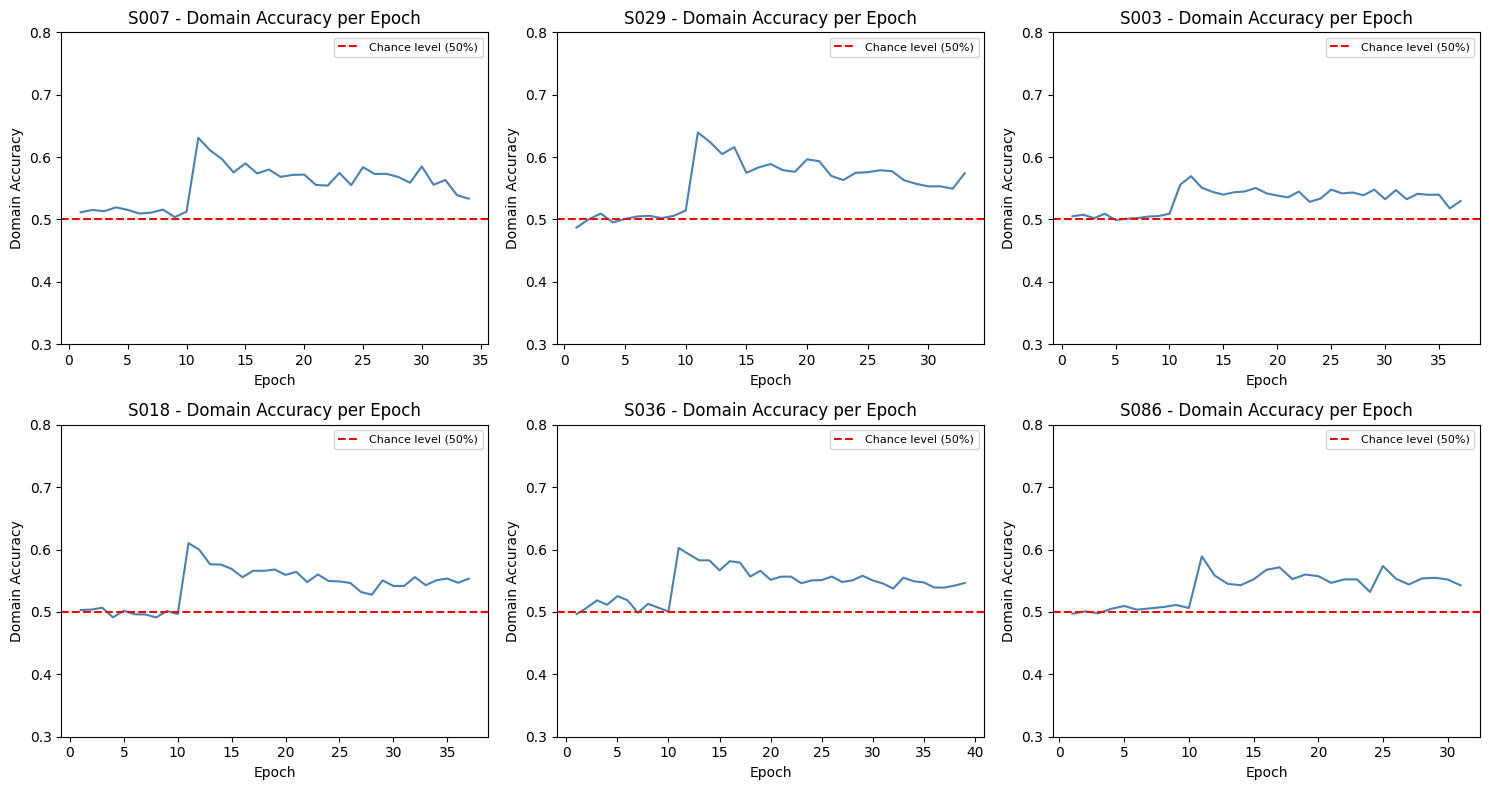

Per epoch domain accuracy plot saved


In [84]:
# three views: per epoch, subject level, overall distribution

# extract domain accuracy per epoch for a few representative subjects
# using seed 42 results which we already loaded

subjects_to_plot = ['S007', 'S029', 'S003', 'S018', 'S036', 'S086']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for idx, subject_id in enumerate(subjects_to_plot):
    if subject_id in seed42_results:
        log = seed42_results[subject_id]['kappa_stopping']['log']
        domain_acc = log['domain_accuracy']
        epochs = log['epoch']

        axes[idx].plot(epochs, domain_acc, color='steelblue', linewidth=1.5)
        axes[idx].axhline(y=0.5, color='red', linestyle='--',
                          label='Chance level (50%)')
        axes[idx].set_title(f'{subject_id} - Domain Accuracy per Epoch')
        axes[idx].set_xlabel('Epoch')
        axes[idx].set_ylabel('Domain Accuracy')
        axes[idx].set_ylim(0.3, 0.8)
        axes[idx].legend(fontsize=8)

plt.tight_layout()
plt.savefig(figures_path / 'domain_accuracy_per_epoch.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("Per epoch domain accuracy plot saved")

#### Per Subject

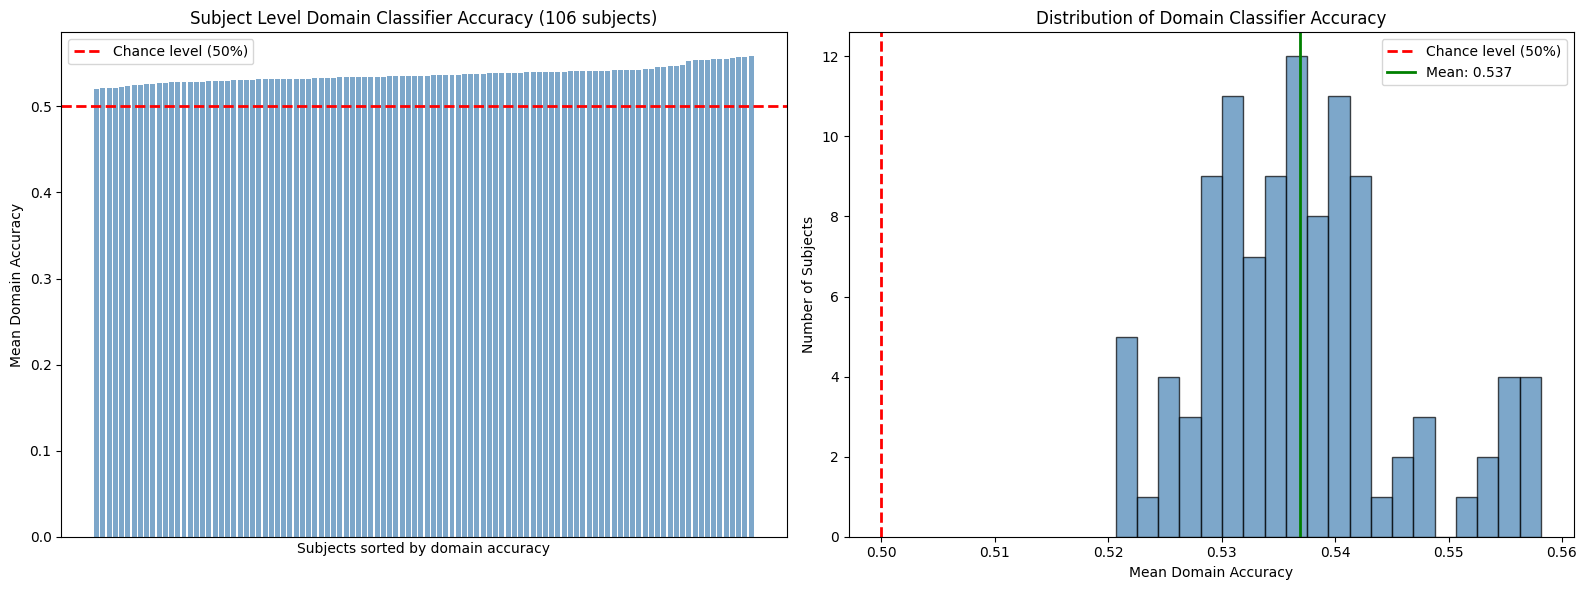

Total subjects: 106
Mean domain accuracy: 0.5369
Subjects below 0.55: 95/106
Subjects below 0.50: 0/106


In [85]:
# subject level domain accuracy
# mean domain accuracy per subject across all epochs

subject_domain_acc = []
for subject_id, subject_data in seed42_results.items():
    if subject_data and 'kappa_stopping' in subject_data:
        log = subject_data['kappa_stopping']['log']
        if 'domain_accuracy' in log and log['domain_accuracy']:
            mean_da = np.mean(log['domain_accuracy'])
            final_kappa = subject_data['kappa_stopping']['final_kappa']
            subject_domain_acc.append({
                'subject_id': subject_id,
                'mean_domain_accuracy': mean_da,
                'final_kappa': final_kappa
            })

da_df = pd.DataFrame(subject_domain_acc)
da_df = da_df.sort_values('mean_domain_accuracy')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# plot 1: subject level domain accuracy sorted
axes[0].bar(range(len(da_df)), da_df['mean_domain_accuracy'],
            color='steelblue', alpha=0.7)
axes[0].axhline(y=0.5, color='red', linestyle='--',
                label='Chance level (50%)', linewidth=2)
axes[0].set_xlabel('Subjects sorted by domain accuracy')
axes[0].set_ylabel('Mean Domain Accuracy')
axes[0].set_title('Subject Level Domain Classifier Accuracy (106 subjects)')
axes[0].legend()
axes[0].set_xticks([])

# plot 2: distribution of domain accuracy
axes[1].hist(da_df['mean_domain_accuracy'], bins=20,
             color='steelblue', alpha=0.7, edgecolor='black')
axes[1].axvline(x=0.5, color='red', linestyle='--',
                label='Chance level (50%)', linewidth=2)
axes[1].axvline(x=da_df['mean_domain_accuracy'].mean(),
                color='green', linestyle='-',
                label=f"Mean: {da_df['mean_domain_accuracy'].mean():.3f}",
                linewidth=2)
axes[1].set_xlabel('Mean Domain Accuracy')
axes[1].set_ylabel('Number of Subjects')
axes[1].set_title('Distribution of Domain Classifier Accuracy')
axes[1].legend()

plt.tight_layout()
plt.savefig(figures_path / 'domain_accuracy_subject_level.png',
            dpi=150, bbox_inches='tight')
plt.show()

print(f"Total subjects: {len(da_df)}")
print(f"Mean domain accuracy: {da_df['mean_domain_accuracy'].mean():.4f}")
print(f"Subjects below 0.55: {(da_df['mean_domain_accuracy'] < 0.55).sum()}/106")
print(f"Subjects below 0.50: {(da_df['mean_domain_accuracy'] < 0.50).sum()}/106")

In [86]:
# task classifier accuracy summary
task_acc_data = []
for subject_id, subject_data in seed42_results.items():
    if subject_data and 'kappa_stopping' in subject_data:
        task_acc_data.append({
            'subject_id': subject_id,
            'task_accuracy': subject_data['kappa_stopping']['final_accuracy'],
            'task_kappa': subject_data['kappa_stopping']['final_kappa']
        })

task_df = pd.DataFrame(task_acc_data)

print("Task classifier accuracy across 106 subjects:")
print(f"  Mean accuracy:   {task_df['task_accuracy'].mean():.4f}")
print(f"  Median accuracy: {task_df['task_accuracy'].median():.4f}")
print(f"  Std accuracy:    {task_df['task_accuracy'].std():.4f}")
print(f"  Min accuracy:    {task_df['task_accuracy'].min():.4f}")
print(f"  Max accuracy:    {task_df['task_accuracy'].max():.4f}")
print(f"  Above 60%:       {(task_df['task_accuracy'] > 0.6).sum()}/106")
print(f"  Above 70%:       {(task_df['task_accuracy'] > 0.7).sum()}/106")
print(f"  Above 80%:       {(task_df['task_accuracy'] > 0.8).sum()}/106")

Task classifier accuracy across 106 subjects:
  Mean accuracy:   0.7531
  Median accuracy: 0.7500
  Std accuracy:    0.1214
  Min accuracy:    0.4773
  Max accuracy:    0.9778
  Above 60%:       95/106
  Above 70%:       67/106
  Above 80%:       42/106


In [87]:
# load CDAN results
with open(results_path / 'loso_results_cdan.json', 'r') as f:
    cdan_results = json.load(f)

with open(results_path / 'loso_results_cdan_seed42.json', 'r') as f:
    cdan_seed42_results = json.load(f)

with open(results_path / 'loso_results_cdan_seed7.json', 'r') as f:
    cdan_seed7_results = json.load(f)

# build dataframes
cdan_data = []
for subject_id, subject_data in cdan_results.items():
    if subject_data and 'kappa_stopping' in subject_data:
        cdan_data.append({
            'subject_id': subject_id,
            'cdan_kappa_kappa': subject_data['kappa_stopping']['final_kappa'],
            'cdan_composite_kappa': subject_data['composite_stopping']['final_kappa']
        })

cdan_df = pd.DataFrame(cdan_data)

print(f"CDAN subjects loaded: {len(cdan_df)}")
print(f"\nCDAN kappa stopping:    mean {cdan_df['cdan_kappa_kappa'].mean():.4f} | median {cdan_df['cdan_kappa_kappa'].median():.4f} | std {cdan_df['cdan_kappa_kappa'].std():.4f} | above chance {(cdan_df['cdan_kappa_kappa']>0.1).sum()}/106")
print(f"CDAN composite stopping: mean {cdan_df['cdan_composite_kappa'].mean():.4f} | median {cdan_df['cdan_composite_kappa'].median():.4f} | std {cdan_df['cdan_composite_kappa'].std():.4f} | above chance {(cdan_df['cdan_composite_kappa']>0.1).sum()}/106")

CDAN subjects loaded: 106

CDAN kappa stopping:    mean 0.5180 | median 0.4990 | std 0.2322 | above chance 102/106
CDAN composite stopping: mean 0.5224 | median 0.5023 | std 0.2306 | above chance 104/106


In [88]:
# build seed dataframes
cdan_s42_data = []
for subject_id, subject_data in cdan_seed42_results.items():
    if subject_data and 'kappa_stopping' in subject_data:
        cdan_s42_data.append({
            'subject_id': subject_id,
            'kappa': subject_data['kappa_stopping']['final_kappa'],
            'composite': subject_data['composite_stopping']['final_kappa']
        })

cdan_s7_data = []
for subject_id, subject_data in cdan_seed7_results.items():
    if subject_data and 'kappa_stopping' in subject_data:
        cdan_s7_data.append({
            'subject_id': subject_id,
            'kappa': subject_data['kappa_stopping']['final_kappa'],
            'composite': subject_data['composite_stopping']['final_kappa']
        })

s42_df = pd.DataFrame(cdan_s42_data)
s7_df = pd.DataFrame(cdan_s7_data)

print("CDAN Seed 42:")
print(f"  Kappa:     mean {s42_df['kappa'].mean():.4f} | median {s42_df['kappa'].median():.4f} | std {s42_df['kappa'].std():.4f} | above chance {(s42_df['kappa']>0.1).sum()}/106")
print(f"  Composite: mean {s42_df['composite'].mean():.4f} | median {s42_df['composite'].median():.4f} | std {s42_df['composite'].std():.4f} | above chance {(s42_df['composite']>0.1).sum()}/106")

print("\nCDAN Seed 7:")
print(f"  Kappa:     mean {s7_df['kappa'].mean():.4f} | median {s7_df['kappa'].median():.4f} | std {s7_df['kappa'].std():.4f} | above chance {(s7_df['kappa']>0.1).sum()}/106")
print(f"  Composite: mean {s7_df['composite'].mean():.4f} | median {s7_df['composite'].median():.4f} | std {s7_df['composite'].std():.4f} | above chance {(s7_df['composite']>0.1).sum()}/106")

CDAN Seed 42:
  Kappa:     mean 0.5160 | median 0.5221 | std 0.2351 | above chance 104/106
  Composite: mean 0.5278 | median 0.5303 | std 0.2298 | above chance 103/106

CDAN Seed 7:
  Kappa:     mean 0.5140 | median 0.5104 | std 0.2414 | above chance 104/106
  Composite: mean 0.5142 | median 0.5469 | std 0.2345 | above chance 104/106


In [89]:
# full comparison table including CDAN
print("Full comparison across all configurations:")
print(f"{'Method':<35} {'Mean':>8} {'Median':>8} {'Std':>8} {'Above 0.1':>10}")
print("-" * 73)

print(f"{'Baseline':<35} {baseline_df['baseline_kappa'].mean():>8.4f} {baseline_df['baseline_kappa'].median():>8.4f} {baseline_df['baseline_kappa'].std():>8.4f} {(baseline_df['baseline_kappa']>0.1).sum():>8}/106")

print(f"{'Warmup DANN (composite)':<35} {warmup_df['warmup_composite_kappa'].mean():>8.4f} {warmup_df['warmup_composite_kappa'].median():>8.4f} {warmup_df['warmup_composite_kappa'].std():>8.4f} {(warmup_df['warmup_composite_kappa']>0.1).sum():>8}/106")

print(f"{'GP+Warmup (kappa)':<35} {gp_df['gp_kappa_kappa'].mean():>8.4f} {gp_df['gp_kappa_kappa'].median():>8.4f} {gp_df['gp_kappa_kappa'].std():>8.4f} {(gp_df['gp_kappa_kappa']>0.1).sum():>8}/106")

print(f"{'GP+Warmup (composite)':<35} {gp_df['gp_composite_kappa'].mean():>8.4f} {gp_df['gp_composite_kappa'].median():>8.4f} {gp_df['gp_composite_kappa'].std():>8.4f} {(gp_df['gp_composite_kappa']>0.1).sum():>8}/106")

print(f"{'CDAN (kappa)':<35} {cdan_df['cdan_kappa_kappa'].mean():>8.4f} {cdan_df['cdan_kappa_kappa'].median():>8.4f} {cdan_df['cdan_kappa_kappa'].std():>8.4f} {(cdan_df['cdan_kappa_kappa']>0.1).sum():>8}/106")

print(f"{'CDAN (composite)':<35} {cdan_df['cdan_composite_kappa'].mean():>8.4f} {cdan_df['cdan_composite_kappa'].median():>8.4f} {cdan_df['cdan_composite_kappa'].std():>8.4f} {(cdan_df['cdan_composite_kappa']>0.1).sum():>8}/106")

print(f"{'CDAN seed42 (composite)':<35} {s42_df['composite'].mean():>8.4f} {s42_df['composite'].median():>8.4f} {s42_df['composite'].std():>8.4f} {(s42_df['composite']>0.1).sum():>8}/106")

print(f"{'CDAN seed7 (composite)':<35} {s7_df['composite'].mean():>8.4f} {s7_df['composite'].median():>8.4f} {s7_df['composite'].std():>8.4f} {(s7_df['composite']>0.1).sum():>8}/106")

Full comparison across all configurations:
Method                                  Mean   Median      Std  Above 0.1
-------------------------------------------------------------------------
Baseline                              0.4996   0.5109   0.2407      102/106
Warmup DANN (composite)               0.5142   0.5445   0.2306      103/106
GP+Warmup (kappa)                     0.5154   0.5052   0.2246      105/106
GP+Warmup (composite)                 0.5070   0.5020   0.2374      103/106
CDAN (kappa)                          0.5180   0.4990   0.2322      102/106
CDAN (composite)                      0.5224   0.5023   0.2306      104/106
CDAN seed42 (composite)               0.5278   0.5303   0.2298      103/106
CDAN seed7 (composite)                0.5142   0.5469   0.2345      104/106


#### Warmup 30 analysis

In [90]:
with open(results_path / 'loso_results_warmup30.json', 'r') as f:
    warmup30_results = json.load(f)

w30_data = []
for subject_id, subject_data in warmup30_results.items():
    if subject_data and 'kappa_stopping' in subject_data:
        w30_data.append({
            'subject_id': subject_id,
            'kappa': subject_data['kappa_stopping']['final_kappa'],
            'composite': subject_data['composite_stopping']['final_kappa']
        })

w30_df = pd.DataFrame(w30_data)

print(f"Warmup 30 results loaded: {len(w30_df)} subjects")
print(f"\nWarmup 30 kappa stopping:    mean {w30_df['kappa'].mean():.4f} | median {w30_df['kappa'].median():.4f} | std {w30_df['kappa'].std():.4f} | above chance {(w30_df['kappa']>0.1).sum()}/106")
print(f"Warmup 30 composite stopping: mean {w30_df['composite'].mean():.4f} | median {w30_df['composite'].median():.4f} | std {w30_df['composite'].std():.4f} | above chance {(w30_df['composite']>0.1).sum()}/106")

print(f"\nFor comparison:")
print(f"CDAN base composite: mean {cdan_df['cdan_composite_kappa'].mean():.4f} | above chance {(cdan_df['cdan_composite_kappa']>0.1).sum()}/106")

Warmup 30 results loaded: 106 subjects

Warmup 30 kappa stopping:    mean 0.5191 | median 0.5284 | std 0.2370 | above chance 101/106
Warmup 30 composite stopping: mean 0.5166 | median 0.5241 | std 0.2405 | above chance 103/106

For comparison:
CDAN base composite: mean 0.5224 | above chance 104/106


### Source and domain accuracy

In [91]:
with open(results_path / 'loso_results_cdan.json', 'r') as f:
    cdan_results = json.load(f)

print(f"Loaded {len(cdan_results)} subjects")
# check if CDAN results already have per-class domain accuracy
sample_subject = list(cdan_results.keys())[0]
sample_log = cdan_results[sample_subject]['kappa_stopping']['log']

print(f"Keys in log: {list(sample_log.keys())}")
print(f"\nHas source_domain_accuracy: {'source_domain_accuracy' in sample_log}")
print(f"Has target_domain_accuracy: {'target_domain_accuracy' in sample_log}")

if 'source_domain_accuracy' in sample_log:
    print(f"\nSample values for {sample_subject}:")
    print(f"source_domain_accuracy: {sample_log['source_domain_accuracy'][:5]}")
    print(f"target_domain_accuracy: {sample_log['target_domain_accuracy'][:5]}")

Loaded 106 subjects
Keys in log: ['epoch', 'class_loss', 'domain_loss', 'accuracy', 'kappa', 'auc', 'alpha', 'learning_rate', 'best_weights_saved', 'domain_accuracy', 'source_domain_accuracy', 'target_domain_accuracy', 'pre_mmd_bandpower_multiscale', 'pre_mmd_bandpower_optimal', 'pre_mmd_bandpower_optimal_bandwidth', 'pre_riemannian', 'post_mmd_bandpower_multiscale', 'post_mmd_bandpower_optimal', 'post_mmd_bandpower_optimal_bandwidth', 'post_riemannian', 'post_mmd_embedding_multiscale', 'post_mmd_embedding_optimal', 'post_mmd_embedding_optimal_bandwidth', 'best_epoch', 'best_kappa', 'total_epochs_run', 'early_stopping_triggered', 'adaptation_quality', 'initial_domain_loss', 'final_domain_loss', 'final_accuracy', 'final_kappa', 'final_auc']

Has source_domain_accuracy: True
Has target_domain_accuracy: True

Sample values for S001:
source_domain_accuracy: [0.5778017241379311, 0.4086206896551724, 0.30711206896551724, 0.39806034482758623, 0.5101293103448276]
target_domain_accuracy: [0.4064

In [92]:
source_means = []
target_means = []
combined_means = []

for subject_id, subject_data in cdan_results.items():
    if subject_data and 'kappa_stopping' in subject_data:
        log = subject_data['kappa_stopping']['log']
        # take post-warmup epochs only (epoch 11 onwards)
        epochs = log['epoch']
        src_acc = log['source_domain_accuracy']
        tgt_acc = log['target_domain_accuracy']
        comb_acc = log['domain_accuracy']

        # indices where epoch > 10 (post warmup)
        post_warmup_idx = [i for i, e in enumerate(epochs) if e > 10]

        if post_warmup_idx:
            source_means.append(np.mean([src_acc[i] for i in post_warmup_idx]))
            target_means.append(np.mean([tgt_acc[i] for i in post_warmup_idx]))
            combined_means.append(np.mean([comb_acc[i] for i in post_warmup_idx]))

print(f"Subjects included: {len(source_means)}")
print(f"\nPost-warmup (adversarial phase active) domain accuracy across 106 subjects:")
print(f"  Mean SOURCE accuracy: {np.mean(source_means):.4f} (std {np.std(source_means):.4f})")
print(f"  Mean TARGET accuracy: {np.mean(target_means):.4f} (std {np.std(target_means):.4f})")
print(f"  Mean COMBINED accuracy: {np.mean(combined_means):.4f} (std {np.std(combined_means):.4f})")
print(f"\n  Difference (source - target): {np.mean(source_means) - np.mean(target_means):+.4f}")

print(f"\nIn plain terms:")
print(f"  Source domain accuracy: {np.mean(source_means)*100:.2f}% (chance level)")
print(f"  Target domain accuracy: {np.mean(target_means)*100:.2f}%")
print(f"  Combined domain accuracy: {np.mean(combined_means)*100:.2f}%")
print(f"  Subjects evaluated: 106/106")

Subjects included: 106

Post-warmup (adversarial phase active) domain accuracy across 106 subjects:
  Mean SOURCE accuracy: 0.5004 (std 0.0410)
  Mean TARGET accuracy: 0.5883 (std 0.0362)
  Mean COMBINED accuracy: 0.5444 (std 0.0112)

  Difference (source - target): -0.0879

In plain terms:
  Source domain accuracy: 50.04% (chance level)
  Target domain accuracy: 58.83%
  Combined domain accuracy: 54.44%
  Subjects evaluated: 106/106


### EEGSym check

In [93]:
with open(results_path / 'loso_results_cdan.json', 'r') as f:
    cdan_results = json.load(f)

cdan_data = []
for subject_id, subject_data in cdan_results.items():
    if subject_data and 'kappa_stopping' in subject_data:
        cdan_data.append({
            'subject_id': subject_id,
            'cdan_kappa_kappa': subject_data['kappa_stopping']['final_kappa'],
            'cdan_composite_kappa': subject_data['composite_stopping']['final_kappa']
        })

cdan_df = pd.DataFrame(cdan_data)
print(f"CDAN reloaded: {len(cdan_df)} subjects")

CDAN reloaded: 106 subjects


In [94]:
with open(results_path / 'loso_results_eegsym.json', 'r') as f:
    eegsym_results = json.load(f)

eegsym_data = []
for subject_id, subject_data in eegsym_results.items():
    if subject_data and 'kappa_stopping' in subject_data:
        eegsym_data.append({
            'subject_id': subject_id,
            'eegsym_kappa_kappa': subject_data['kappa_stopping']['final_kappa'],
            'eegsym_composite_kappa': subject_data['composite_stopping']['final_kappa']
        })

eegsym_df = pd.DataFrame(eegsym_data)

print(f"EEGSym subjects loaded: {len(eegsym_df)}")
print(f"\nEEGSym kappa stopping:    mean {eegsym_df['eegsym_kappa_kappa'].mean():.4f} | median {eegsym_df['eegsym_kappa_kappa'].median():.4f} | std {eegsym_df['eegsym_kappa_kappa'].std():.4f} | above chance {(eegsym_df['eegsym_kappa_kappa']>0.1).sum()}/106")
print(f"EEGSym composite stopping: mean {eegsym_df['eegsym_composite_kappa'].mean():.4f} | median {eegsym_df['eegsym_composite_kappa'].median():.4f} | std {eegsym_df['eegsym_composite_kappa'].std():.4f} | above chance {(eegsym_df['eegsym_composite_kappa']>0.1).sum()}/106")

print(f"\nFor comparison, CDAN (best so far):")
print(f"CDAN composite: mean {cdan_df['cdan_composite_kappa'].mean():.4f} | above chance {(cdan_df['cdan_composite_kappa']>0.1).sum()}/106")

EEGSym subjects loaded: 106

EEGSym kappa stopping:    mean 0.4691 | median 0.4453 | std 0.2068 | above chance 104/106
EEGSym composite stopping: mean 0.4674 | median 0.4536 | std 0.2028 | above chance 103/106

For comparison, CDAN (best so far):
CDAN composite: mean 0.5224 | above chance 104/106


In [95]:
import json

configs = {
    'augmentation': 'subset60_augmentation.json',
    'embed256': 'subset60_embed256.json',
    'dropout0.15': 'subset60_dropout0.15.json',
    'dropout0.35': 'subset60_dropout0.35.json',
    'lambda0.3': 'subset60_lambda0.3.json',
    'lambda0.9': 'subset60_lambda0.9.json',
    'nadam': 'subset60_optimizer_nadam.json',
    'sgd': 'subset60_optimizer_sgd.json',
}

results_summary = {}

for label, filename in configs.items():
    with open(results_path / filename, 'r') as f:
        data = json.load(f)
    kappas = [v['kappa_stopping']['final_kappa'] for v in data.values()
              if v and 'kappa_stopping' in v]
    results_summary[label] = {
        'mean': sum(kappas) / len(kappas),
        'median': sorted(kappas)[len(kappas)//2],
        'n': len(kappas),
        'above_chance': sum(1 for k in kappas if k > 0.1)
    }

print(f"{'Config':<15} {'Mean':>8} {'Median':>8} {'N':>5} {'Above0.1':>10}")
print("-" * 50)
for label, stats in results_summary.items():
    print(f"{label:<15} {stats['mean']:>8.4f} {stats['median']:>8.4f} {stats['n']:>5} {stats['above_chance']:>10}/{stats['n']}")

Config              Mean   Median     N   Above0.1
--------------------------------------------------
augmentation      0.4635   0.4270    60         58/60
embed256          0.4783   0.4727    60         58/60
dropout0.15       0.4673   0.4664    60         60/60
dropout0.35       0.4551   0.4286    60         58/60
lambda0.3         0.4726   0.4248    60         59/60
lambda0.9         0.4751   0.4310    60         59/60
nadam             0.4577   0.4611    60         58/60
sgd               0.2178   0.1739    60         50/60


In [96]:
subset_60 = ['S002', 'S003', 'S005', 'S006', 'S009', 'S010', 'S012', 'S013', 'S014', 'S015', 'S016', 'S017', 'S021', 'S024', 'S025', 'S026', 'S028', 'S029', 'S032', 'S033', 'S035', 'S036', 'S038', 'S040', 'S041', 'S046', 'S047', 'S049', 'S050', 'S052', 'S053', 'S054', 'S055', 'S057', 'S059', 'S061', 'S062', 'S066', 'S068', 'S071', 'S073', 'S074', 'S075', 'S076', 'S078', 'S080', 'S081', 'S082', 'S086', 'S089', 'S090', 'S094', 'S097', 'S098', 'S099', 'S101', 'S102', 'S103', 'S105', 'S106']

In [97]:
with open(results_path / 'loso_results_cdan.json', 'r') as f:
    cdan_full = json.load(f)

baseline_kappas = [cdan_full[s]['kappa_stopping']['final_kappa']
                    for s in subset_60 if s in cdan_full]

baseline_stats = {
    'mean': sum(baseline_kappas) / len(baseline_kappas),
    'median': sorted(baseline_kappas)[len(baseline_kappas)//2],
    'n': len(baseline_kappas),
    'above_chance': sum(1 for k in baseline_kappas if k > 0.1)
}
print(f"{'baseline(CDAN)':<15} {baseline_stats['mean']:>8.4f} {baseline_stats['median']:>8.4f} {baseline_stats['n']:>5} {baseline_stats['above_chance']:>10}/{baseline_stats['n']}")

baseline(CDAN)    0.4976   0.4675    60         58/60


### EPoch window analysis

In [98]:
with open(results_path / 'subset60_epochwindow.json', 'r') as f:
    epochwindow_data = json.load(f)

kappas = [v['kappa_stopping']['final_kappa'] for v in epochwindow_data.values()
          if v and 'kappa_stopping' in v]

print(f"{'Config':<15} {'Mean':>8} {'Median':>8} {'N':>5} {'Above0.1':>10}")
print("-" * 50)
print(f"{'epochwindow':<15} {sum(kappas)/len(kappas):>8.4f} {sorted(kappas)[len(kappas)//2]:>8.4f} {len(kappas):>5} {sum(1 for k in kappas if k>0.1):>10}/{len(kappas)}")
print(f"{'baseline(CDAN)':<15} {0.4976:>8.4f} {0.4675:>8.4f} {60:>5} {58:>10}/60")

Config              Mean   Median     N   Above0.1
--------------------------------------------------
epochwindow       0.4352   0.4407    60         55/60
baseline(CDAN)    0.4976   0.4675    60         58/60


### 16 channel and multiclass subset check

In [99]:
with open(results_path / 'subset60_16ch.json', 'r') as f:
    ch16_data = json.load(f)
ch16_kappas = [v['kappa_stopping']['final_kappa'] for v in ch16_data.values() if v and 'kappa_stopping' in v]

with open(results_path / 'subset60_multiclass.json', 'r') as f:
    mc_data = json.load(f)
mc_kappas = [v['kappa_stopping']['final_kappa'] for v in mc_data.values() if v and 'kappa_stopping' in v]

print(f"{'Config':<15} {'Mean':>8} {'Median':>8} {'N':>5} {'Above0.1':>10}")
print("-" * 50)
print(f"{'16ch':<15} {sum(ch16_kappas)/len(ch16_kappas):>8.4f} {sorted(ch16_kappas)[len(ch16_kappas)//2]:>8.4f} {len(ch16_kappas):>5} {sum(1 for k in ch16_kappas if k>0.1):>10}/{len(ch16_kappas)}")
print(f"{'multiclass':<15} {sum(mc_kappas)/len(mc_kappas):>8.4f} {sorted(mc_kappas)[len(mc_kappas)//2]:>8.4f} {len(mc_kappas):>5} {sum(1 for k in mc_kappas if k>0.1):>10}/{len(mc_kappas)}")
print(f"{'baseline(CDAN)':<15} {0.4976:>8.4f} {0.4675:>8.4f} {60:>5} {58:>10}/60")

Config              Mean   Median     N   Above0.1
--------------------------------------------------
16ch              0.4613   0.4545    60         59/60
multiclass        0.2716   0.2241    60         52/60
baseline(CDAN)    0.4976   0.4675    60         58/60


### 16 channel full run

In [100]:
with open(results_path / 'loso_results_16ch.json', 'r') as f:
    ch16_full = json.load(f)

kappa_vals = [v['kappa_stopping']['final_kappa'] for v in ch16_full.values() if v and 'kappa_stopping' in v]
composite_vals = [v['composite_stopping']['final_kappa'] for v in ch16_full.values() if v and 'composite_stopping' in v]

print(f"{'Stopping':<12} {'Mean':>8} {'Median':>8} {'N':>5} {'Above0.1':>10}")
print("-" * 50)
print(f"{'kappa':<12} {sum(kappa_vals)/len(kappa_vals):>8.4f} {sorted(kappa_vals)[len(kappa_vals)//2]:>8.4f} {len(kappa_vals):>5} {sum(1 for k in kappa_vals if k>0.1):>10}/{len(kappa_vals)}")
print(f"{'composite':<12} {sum(composite_vals)/len(composite_vals):>8.4f} {sorted(composite_vals)[len(composite_vals)//2]:>8.4f} {len(composite_vals):>5} {sum(1 for k in composite_vals if k>0.1):>10}/{len(composite_vals)}")
print(f"\nbaseline(CDAN) for reference: mean ~0.515-0.528 range across seeds, ~103-105/106 above chance")

Stopping         Mean   Median     N   Above0.1
--------------------------------------------------
kappa          0.5387   0.5455   106        102/106
composite      0.5366   0.5501   106        103/106

baseline(CDAN) for reference: mean ~0.515-0.528 range across seeds, ~103-105/106 above chance


#### Multi class 106 subjects check

In [101]:
with open(results_path / 'loso_results_multiclass.json', 'r') as f:
    mc_full = json.load(f)

mc_kappa = [v['kappa_stopping']['final_kappa'] for v in mc_full.values() if v and 'kappa_stopping' in v]
mc_composite = [v['composite_stopping']['final_kappa'] for v in mc_full.values() if v and 'composite_stopping' in v]

print(f"{'Stopping':<12} {'Mean':>8} {'Median':>8} {'N':>5} {'Above0.1':>10}")
print("-" * 50)
print(f"{'kappa':<12} {sum(mc_kappa)/len(mc_kappa):>8.4f} {sorted(mc_kappa)[len(mc_kappa)//2]:>8.4f} {len(mc_kappa):>5} {sum(1 for k in mc_kappa if k>0.1):>10}/{len(mc_kappa)}")
print(f"{'composite':<12} {sum(mc_composite)/len(mc_composite):>8.4f} {sorted(mc_composite)[len(mc_composite)//2]:>8.4f} {len(mc_composite):>5} {sum(1 for k in mc_composite if k>0.1):>10}/{len(mc_composite)}")

Stopping         Mean   Median     N   Above0.1
--------------------------------------------------
kappa          0.3182   0.2874   106         97/106
composite      0.3192   0.2930   106         95/106


In [102]:
import numpy as np

per_class_acc_all = {0: [], 1: [], 2: [], 3: []}

for subject_id, subject_data in mc_full.items():
    if subject_data and 'kappa_stopping' in subject_data:
        pca = subject_data['kappa_stopping']['log']['final_per_class_accuracy']
        if pca:
            for cls_str, acc in pca.items():
                per_class_acc_all[int(cls_str)].append(acc)

print("Per-class accuracy across all 106 subjects:")
print(f"{'Class':<25} {'Mean':>8} {'Median':>8} {'Std':>8}")
print("-" * 55)
class_names = {0: 'left fist', 1: 'right fist', 2: 'both fists', 3: 'both feet'}
for cls in [0, 1, 2, 3]:
    accs = per_class_acc_all[cls]
    print(f"{cls} ({class_names[cls]}):  {np.mean(accs):>8.4f} {np.median(accs):>8.4f} {np.std(accs):>8.4f}")

Per-class accuracy across all 106 subjects:
Class                         Mean   Median      Std
-------------------------------------------------------
0 (left fist):    0.5179   0.5109   0.1875
1 (right fist):    0.4589   0.4564   0.2091
2 (both fists):    0.4821   0.4545   0.2016
3 (both feet):    0.4985   0.4772   0.2130


### 16 ch seed 42 check

In [103]:
with open(results_path / 'loso_results_16ch.json', 'r') as f:
    ch16_base = json.load(f)
with open(results_path / 'loso_results_16ch_seed42.json', 'r') as f:
    ch16_seed42 = json.load(f)

base_kappa = [v['kappa_stopping']['final_kappa'] for v in ch16_base.values() if v and 'kappa_stopping' in v]
base_composite = [v['composite_stopping']['final_kappa'] for v in ch16_base.values() if v and 'composite_stopping' in v]
seed_kappa = [v['kappa_stopping']['final_kappa'] for v in ch16_seed42.values() if v and 'kappa_stopping' in v]
seed_composite = [v['composite_stopping']['final_kappa'] for v in ch16_seed42.values() if v and 'composite_stopping' in v]

print(f"{'Run':<20} {'Mean':>8} {'Median':>8} {'N':>5} {'Above0.1':>10}")
print("-" * 58)
print(f"{'base (kappa)':<20} {sum(base_kappa)/len(base_kappa):>8.4f} {sorted(base_kappa)[len(base_kappa)//2]:>8.4f} {len(base_kappa):>5} {sum(1 for k in base_kappa if k>0.1):>10}/{len(base_kappa)}")
print(f"{'seed42 (kappa)':<20} {sum(seed_kappa)/len(seed_kappa):>8.4f} {sorted(seed_kappa)[len(seed_kappa)//2]:>8.4f} {len(seed_kappa):>5} {sum(1 for k in seed_kappa if k>0.1):>10}/{len(seed_kappa)}")
print(f"{'base (composite)':<20} {sum(base_composite)/len(base_composite):>8.4f} {sorted(base_composite)[len(base_composite)//2]:>8.4f} {len(base_composite):>5} {sum(1 for k in base_composite if k>0.1):>10}/{len(base_composite)}")
print(f"{'seed42 (composite)':<20} {sum(seed_composite)/len(seed_composite):>8.4f} {sorted(seed_composite)[len(seed_composite)//2]:>8.4f} {len(seed_composite):>5} {sum(1 for k in seed_composite if k>0.1):>10}/{len(seed_composite)}")

Run                      Mean   Median     N   Above0.1
----------------------------------------------------------
base (kappa)           0.5387   0.5455   106        102/106
seed42 (kappa)         0.5509   0.5501   106        105/106
base (composite)       0.5366   0.5501   106        103/106
seed42 (composite)     0.5390   0.5536   106        103/106


### Multi class 8 ch check

#### File check

In [104]:
import json
import numpy as np
import pandas as pd
from pathlib import Path

results_path = Path("../results")
with open(results_path / "loso_results_multiclass.json", "r") as f:
    results = json.load(f)

print(f"Subjects in results: {len(results)}")
print(f"Stopping criteria present for S001: {list(results['S001'].keys())}")

Subjects in results: 106
Stopping criteria present for S001: ['kappa_stopping', 'composite_stopping']


#### extraction func

In [105]:
def get_per_class_accuracy(results, subject_id, criterion='kappa_stopping'):
    log = results[subject_id][criterion]['log']
    pca = log.get('final_per_class_accuracy')
    if pca is None:
        return None  # binary run, not multiclass — shouldn't happen here, but checked anyway
    return {int(k): v for k, v in pca.items()}

def get_confusion_matrix(results, subject_id, criterion='kappa_stopping'):
    log = results[subject_id][criterion]['log']
    cm = log.get('final_confusion_matrix')
    if cm is None:
        return None
    return np.array(cm)

####   summary table.

In [106]:

rows = []
for subject_id, subject_results in results.items():
    row = {'subject_id': subject_id}
    for criterion in ['kappa_stopping', 'composite_stopping']:
        entry = subject_results.get(criterion)
        if entry is None:
            row[f'{criterion}_kappa'] = None
            row[f'{criterion}_accuracy'] = None
            row[f'{criterion}_auc'] = None
            continue
        row[f'{criterion}_kappa'] = entry['final_kappa']
        row[f'{criterion}_accuracy'] = entry['final_accuracy']
        row[f'{criterion}_auc'] = entry['final_auc']
    rows.append(row)

df = pd.DataFrame(rows)
print(df.describe())

       kappa_stopping_kappa  kappa_stopping_accuracy  kappa_stopping_auc  \
count            106.000000               106.000000          106.000000   
mean               0.318212                 0.488347            0.696513   
std                0.195567                 0.146916            0.126479   
min                0.017351                 0.261364            0.454226   
25%                0.155629                 0.363051            0.589510   
50%                0.283164                 0.463218            0.683427   
75%                0.453381                 0.592013            0.798174   
max                0.851925                 0.888889            0.964030   

       composite_stopping_kappa  composite_stopping_accuracy  \
count                106.000000                   106.000000   
mean                   0.319166                     0.489743   
std                    0.188038                     0.140841   
min                    0.010015                     0.25555

#### count how many subjects clear the kappa>0.1

In [107]:
n_above_kappa = (df['kappa_stopping_kappa'] > 0.1).sum()
n_above_composite = (df['composite_stopping_kappa'] > 0.1).sum()
print(f"Above kappa>0.1 (kappa-stopping): {n_above_kappa}/106")
print(f"Above kappa>0.1 (composite-stopping): {n_above_composite}/106")
print(f"Mean kappa (kappa-stopping): {df['kappa_stopping_kappa'].mean():.4f}")
print(f"Mean kappa (composite-stopping): {df['composite_stopping_kappa'].mean():.4f}")

Above kappa>0.1 (kappa-stopping): 97/106
Above kappa>0.1 (composite-stopping): 95/106
Mean kappa (kappa-stopping): 0.3182
Mean kappa (composite-stopping): 0.3192


#### per-class accuracy agg

In [108]:
class_accs = {c: {'kappa_stopping': [], 'composite_stopping': []} for c in range(4)}

for subject_id in results:
    for criterion in ['kappa_stopping', 'composite_stopping']:
        pca = get_per_class_accuracy(results, subject_id, criterion)
        if pca:
            for cls, acc in pca.items():
                class_accs[cls][criterion].append(acc)

class_names = {0: 'left', 1: 'right', 2: 'both-fists', 3: 'both-feet'}
for cls in range(4):
    k_vals = class_accs[cls]['kappa_stopping']
    c_vals = class_accs[cls]['composite_stopping']
    print(f"{class_names[cls]}: kappa-stop mean {np.mean(k_vals):.4f} (n={len(k_vals)}) | "
          f"composite-stop mean {np.mean(c_vals):.4f} (n={len(c_vals)})")

left: kappa-stop mean 0.5179 (n=106) | composite-stop mean 0.5250 (n=106)
right: kappa-stop mean 0.4589 (n=106) | composite-stop mean 0.4703 (n=106)
both-fists: kappa-stop mean 0.4821 (n=106) | composite-stop mean 0.4600 (n=106)
both-feet: kappa-stop mean 0.4985 (n=106) | composite-stop mean 0.5018 (n=106)


#### Confusion Mtrix

In [109]:
def get_confusion_matrix(results, subject_id, criterion='kappa_stopping'):
    log = results[subject_id][criterion]['log']
    cm = log.get('final_confusion_matrix')
    if cm is None:
        return None
    return np.array(cm)

agg_cm_kappa = np.zeros((4, 4))
agg_cm_composite = np.zeros((4, 4))

for subject_id in results:
    cm_k = get_confusion_matrix(results, subject_id, 'kappa_stopping')
    cm_c = get_confusion_matrix(results, subject_id, 'composite_stopping')
    if cm_k is not None:
        agg_cm_kappa += cm_k
    if cm_c is not None:
        agg_cm_composite += cm_c

class_names = ['left', 'right', 'both-fists', 'both-feet']

print("Aggregated confusion matrix (kappa-stopping), raw counts:")
print(pd.DataFrame(agg_cm_kappa, index=class_names, columns=class_names))

row_norm = agg_cm_kappa / agg_cm_kappa.sum(axis=1, keepdims=True)
print("\nRow-normalized (each row = where that true class actually got predicted):")
print(pd.DataFrame(row_norm, index=class_names, columns=class_names).round(3))

Aggregated confusion matrix (kappa-stopping), raw counts:
              left   right  both-fists  both-feet
left        1227.0   288.0       504.0      353.0
right        359.0  1063.0       537.0      358.0
both-fists   481.0   394.0      1104.0      325.0
both-feet    428.0   398.0       338.0     1149.0

Row-normalized (each row = where that true class actually got predicted):
             left  right  both-fists  both-feet
left        0.517  0.121       0.212      0.149
right       0.155  0.459       0.232      0.155
both-fists  0.209  0.171       0.479      0.141
both-feet   0.185  0.172       0.146      0.497


#### Negative transfer subjects

In [110]:
below_threshold_kappa = df[df['kappa_stopping_kappa'] <= 0.1]['subject_id'].tolist()
below_threshold_composite = df[df['composite_stopping_kappa'] <= 0.1]['subject_id'].tolist()

print(f"Below kappa<=0.1, kappa-stopping ({len(below_threshold_kappa)} subjects):")
print(below_threshold_kappa)
print(f"\nBelow kappa<=0.1, composite-stopping ({len(below_threshold_composite)} subjects):")
print(below_threshold_composite)

known_negative_transfer = ['S003', 'S018', 'S036']
print("\nWhere the known binary negative-transfer subjects land in multiclass:")
print(df[df['subject_id'].isin(known_negative_transfer)][
    ['subject_id', 'kappa_stopping_kappa', 'composite_stopping_kappa']
])

Below kappa<=0.1, kappa-stopping (9 subjects):
['S006', 'S009', 'S018', 'S020', 'S037', 'S039', 'S067', 'S097', 'S107']

Below kappa<=0.1, composite-stopping (11 subjects):
['S003', 'S006', 'S018', 'S020', 'S039', 'S053', 'S067', 'S097', 'S099', 'S107', 'S109']

Where the known binary negative-transfer subjects land in multiclass:
   subject_id  kappa_stopping_kappa  composite_stopping_kappa
2        S003              0.115844                  0.082939
17       S018              0.054963                  0.010015
35       S036              0.108823                  0.168528


In [ ]:
check_negative_transfer_k = ['S006', 'S009', 'S018', 'S020', 'S037', 'S039', 'S067', 'S097', 'S107']
print("\nWhere the known binary negative-transfer subjects land in multiclass:")
print(df[df['subject_id'].isin(check_negative_transfer_k)][
    ['subject_id', 'kappa_stopping_kappa', 'composite_stopping_kappa']
])


Where the known binary negative-transfer subjects land in multiclass:
    subject_id  kappa_stopping_kappa  composite_stopping_kappa
2         S003              0.115844                  0.082939
5         S006              0.095403                  0.051383
8         S009              0.034335                  0.132025
17        S018              0.054963                  0.010015
19        S020              0.083619                  0.075435
36        S037              0.086347                  0.112811
38        S039              0.081784                  0.067894
52        S053              0.185911                  0.077086
66        S067              0.081935                  0.068047
94        S097              0.017351                  0.040000
96        S099              0.166416                  0.087563
103       S107              0.077838                  0.064665
105       S109              0.185453                  0.098818


##### negative transfer check for kappa and comp

In [114]:
below_kappa = df[df['kappa_stopping_kappa'] <= 0.1]['subject_id'].tolist()

print("Per-class accuracy for below-threshold subjects (kappa-stopping):\n")
for subj in below_kappa:
    pca = get_per_class_accuracy(results, subj, 'kappa_stopping')
    overall_kappa = results[subj]['kappa_stopping']['final_kappa']
    print(f"{subj} (kappa={overall_kappa:.3f}): "
          f"left={pca[0]:.2f} right={pca[1]:.2f} both-fists={pca[2]:.2f} both-feet={pca[3]:.2f}")

Per-class accuracy for below-threshold subjects (kappa-stopping):

S006 (kappa=0.095): left=0.21 right=0.05 both-fists=0.59 both-feet=0.43
S009 (kappa=0.034): left=0.33 right=0.29 both-fists=0.30 both-feet=0.18
S018 (kappa=0.055): left=0.41 right=0.00 both-fists=0.45 both-feet=0.30
S020 (kappa=0.084): left=0.39 right=0.20 both-fists=0.27 both-feet=0.38
S037 (kappa=0.086): left=0.43 right=0.00 both-fists=0.77 both-feet=0.05
S039 (kappa=0.082): left=0.35 right=0.14 both-fists=0.35 both-feet=0.41
S067 (kappa=0.082): left=0.32 right=0.22 both-fists=0.30 both-feet=0.41
S097 (kappa=0.017): left=0.27 right=0.27 both-fists=0.17 both-feet=0.33
S107 (kappa=0.078): left=0.38 right=0.29 both-fists=0.27 both-feet=0.30


In [116]:
def per_subject_confusion(results, subject_id, criterion='kappa_stopping'):
    cm = get_confusion_matrix(results, subject_id, criterion)
    return pd.DataFrame(cm, index=class_names, columns=class_names)

for subj in ['S006', 'S037','S018' ]:
    print(f"\n{subj} confusion matrix (kappa-stopping), raw counts:")
    print(per_subject_confusion(results, subj))
    cm = get_confusion_matrix(results, subj)
    row_sums = cm.sum(axis=1)
    print(f"Trial counts per true class: left={row_sums[0]:.0f} right={row_sums[1]:.0f} "
          f"both-fists={row_sums[2]:.0f} both-feet={row_sums[3]:.0f}")


S006 confusion matrix (kappa-stopping), raw counts:
            left  right  both-fists  both-feet
left           5      0          11          8
right          3      1           8          9
both-fists     1      2          13          6
both-feet      2      1          10         10
Trial counts per true class: left=24 right=21 both-fists=22 both-feet=23

S037 confusion matrix (kappa-stopping), raw counts:
            left  right  both-fists  both-feet
left          10      0          12          1
right          8      0          14          0
both-fists     5      0          17          0
both-feet      8      0          12          1
Trial counts per true class: left=23 right=22 both-fists=22 both-feet=21

S018 confusion matrix (kappa-stopping), raw counts:
            left  right  both-fists  both-feet
left           9      0           8          5
right          4      0          15          4
both-fists     3      1          10          8
both-feet      5      0          11  

In [117]:
collapse_check = []
for subject_id in results:
    cm = get_confusion_matrix(results, subject_id, 'kappa_stopping')
    if cm is None:
        continue
    total_trials = cm.sum()
    right_predicted = cm[:, 1].sum()  # column 1 = predicted "right"
    collapse_check.append({
        'subject_id': subject_id,
        'right_predicted_frac': right_predicted / total_trials,
        'kappa': results[subject_id]['kappa_stopping']['final_kappa']
    })

collapse_df = pd.DataFrame(collapse_check).sort_values('right_predicted_frac')
print(collapse_df.head(15))
print(f"\nMedian right-predicted fraction across all subjects: {collapse_df['right_predicted_frac'].median():.3f}")
print(f"Expected if balanced: ~0.25")

   subject_id  right_predicted_frac     kappa
36       S037              0.000000  0.086347
17       S018              0.011111  0.054963
29       S030              0.036145  0.300470
80       S081              0.044444  0.144823
5        S006              0.044444  0.095403
39       S040              0.087500  0.155629
89       S091              0.102273  0.261138
65       S066              0.122222  0.126788
9        S010              0.123596  0.472660
34       S035              0.133333  0.554161
7        S008              0.134831  0.431406
38       S039              0.144444  0.081784
15       S016              0.146067  0.160094
82       S083              0.147727  0.393939
25       S026              0.154762  0.347480

Median right-predicted fraction across all subjects: 0.227
Expected if balanced: ~0.25


In [118]:
def get_epoch_class_accuracy_trajectory(results, subject_id, class_idx=1, criterion='kappa_stopping'):
    log = results[subject_id][criterion]['log']
    per_class_list = log['per_class_accuracy']  # list of dicts, one per epoch
    trajectory = []
    for epoch_dict in per_class_list:
        if epoch_dict is None:
            trajectory.append(None)
            continue
        val = epoch_dict.get(class_idx, epoch_dict.get(str(class_idx)))
        trajectory.append(val)
    return trajectory

subjects_to_check = ['S006', 'S037', 'S018', 'S081', 'S091', 'S066']
for subj in subjects_to_check:
    traj = get_epoch_class_accuracy_trajectory(results, subj, class_idx=1)
    vals_str = [f'{v:.2f}' if v is not None else 'None' for v in traj]
    print(f"{subj} - right-class accuracy per epoch:")
    print(vals_str)
    print()

S006 - right-class accuracy per epoch:
['0.29', '0.14', '0.14', '0.10', '0.10', '0.00', '0.05', '0.14', '0.00', '0.14', '0.10', '0.19', '0.19', '0.29', '0.10', '0.14', '0.38', '0.19', '0.24', '0.29', '0.24', '0.19', '0.24', '0.14', '0.24', '0.24', '0.33', '0.24', '0.14', '0.24', '0.24', '0.24', '0.24', '0.24', '0.24', '0.24', '0.24', '0.24', '0.24', '0.24']

S037 - right-class accuracy per epoch:
['0.00', '0.00', '0.00', '0.05', '0.00', '0.00', '0.00', '0.00', '0.05', '0.05', '0.05', '0.05', '0.00', '0.05', '0.00', '0.00', '0.05', '0.05', '0.05', '0.00', '0.05', '0.05', '0.00', '0.05', '0.05', '0.05', '0.05', '0.00', '0.00', '0.00', '0.05', '0.00', '0.00', '0.05', '0.05', '0.05', '0.05']

S018 - right-class accuracy per epoch:
['0.00', '0.04', '0.09', '0.04', '0.00', '0.00', '0.04', '0.00', '0.04', '0.00', '0.04', '0.04', '0.00', '0.04', '0.09', '0.00', '0.04', '0.00', '0.00', '0.04', '0.04', '0.00', '0.00', '0.09', '0.04', '0.04', '0.04', '0.04', '0.09', '0.04', '0.04', '0.04', '0.04'

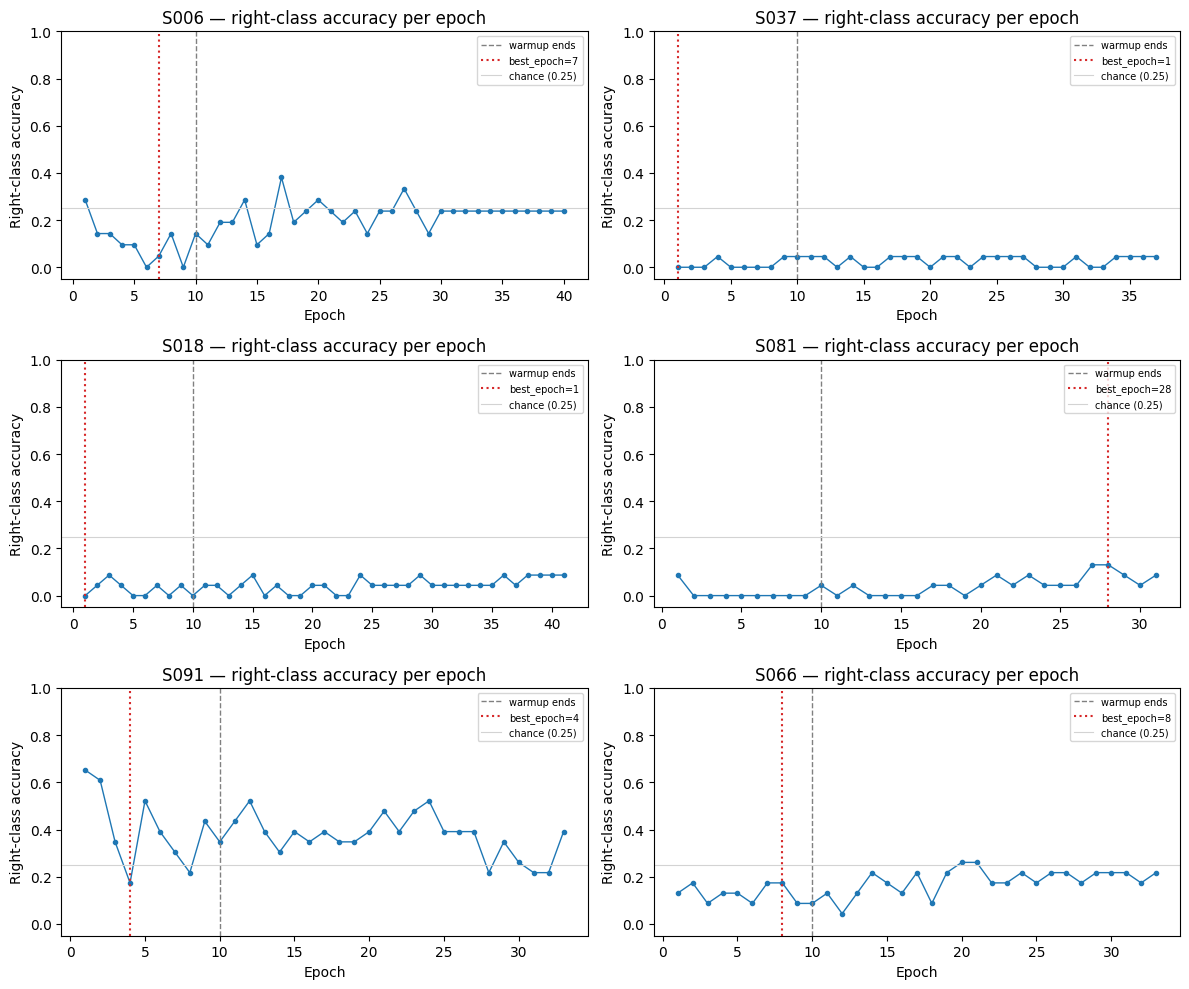

In [121]:
import matplotlib.pyplot as plt

subjects_to_plot = ['S006', 'S037', 'S018', 'S081', 'S091', 'S066']

fig, axes = plt.subplots(3, 2, figsize=(12, 10), sharex=False)
axes = axes.flatten()

for ax, subj in zip(axes, subjects_to_plot):
    log = results[subj]['kappa_stopping']['log']
    right_acc_traj = get_epoch_class_accuracy_trajectory(results, subj, class_idx=1)
    epochs = list(range(1, len(right_acc_traj) + 1))
    best_epoch = log['best_epoch']

    ax.plot(epochs, right_acc_traj, marker='o', markersize=3, linewidth=1, color='tab:blue')
    ax.axvline(x=10, color='gray', linestyle='--', linewidth=1, label='warmup ends')
    ax.axvline(x=best_epoch, color='tab:red', linestyle=':', linewidth=1.5, label=f'best_epoch={best_epoch}')
    ax.axhline(y=0.25, color='lightgray', linestyle='-', linewidth=0.8, label='chance (0.25)')
    ax.set_title(f"{subj} — right-class accuracy per epoch")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Right-class accuracy")
    ax.set_ylim(-0.05, 1.0)
    ax.legend(fontsize=7, loc='upper right')

plt.tight_layout()
plt.savefig('../results/figures/right_class_accuracy_six_subjects.png', dpi=150)
plt.show()

#### Domain Adversarial check for these subjects

In [119]:
for subj in subjects_to_check:
    log = results[subj]['kappa_stopping']['log']
    domain_acc = log['domain_accuracy']
    alpha = log['alpha']
    print(f"{subj} - alpha (GRL ramp) per epoch: {[f'{a:.2f}' for a in alpha]}")
    print(f"{subj} - domain accuracy per epoch: {[f'{d:.2f}' for d in domain_acc]}")
    print()

S006 - alpha (GRL ramp) per epoch: ['0.02', '0.05', '0.07', '0.10', '0.12', '0.15', '0.17', '0.20', '0.22', '0.24', '0.27', '0.29', '0.31', '0.34', '0.36', '0.38', '0.40', '0.42', '0.44', '0.46', '0.48', '0.50', '0.52', '0.54', '0.55', '0.57', '0.59', '0.60', '0.62', '0.64', '0.65', '0.66', '0.68', '0.69', '0.70', '0.72', '0.73', '0.74', '0.75', '0.76']
S006 - domain accuracy per epoch: ['0.50', '0.50', '0.50', '0.50', '0.51', '0.50', '0.50', '0.50', '0.50', '0.50', '0.60', '0.58', '0.55', '0.57', '0.56', '0.56', '0.55', '0.54', '0.55', '0.54', '0.55', '0.54', '0.54', '0.54', '0.53', '0.55', '0.55', '0.54', '0.54', '0.54', '0.54', '0.54', '0.54', '0.54', '0.54', '0.54', '0.54', '0.53', '0.54', '0.54']

S037 - alpha (GRL ramp) per epoch: ['0.02', '0.05', '0.07', '0.10', '0.12', '0.15', '0.17', '0.20', '0.22', '0.24', '0.27', '0.29', '0.31', '0.34', '0.36', '0.38', '0.40', '0.42', '0.44', '0.46', '0.48', '0.50', '0.52', '0.54', '0.55', '0.57', '0.59', '0.60', '0.62', '0.64', '0.65', '0.6

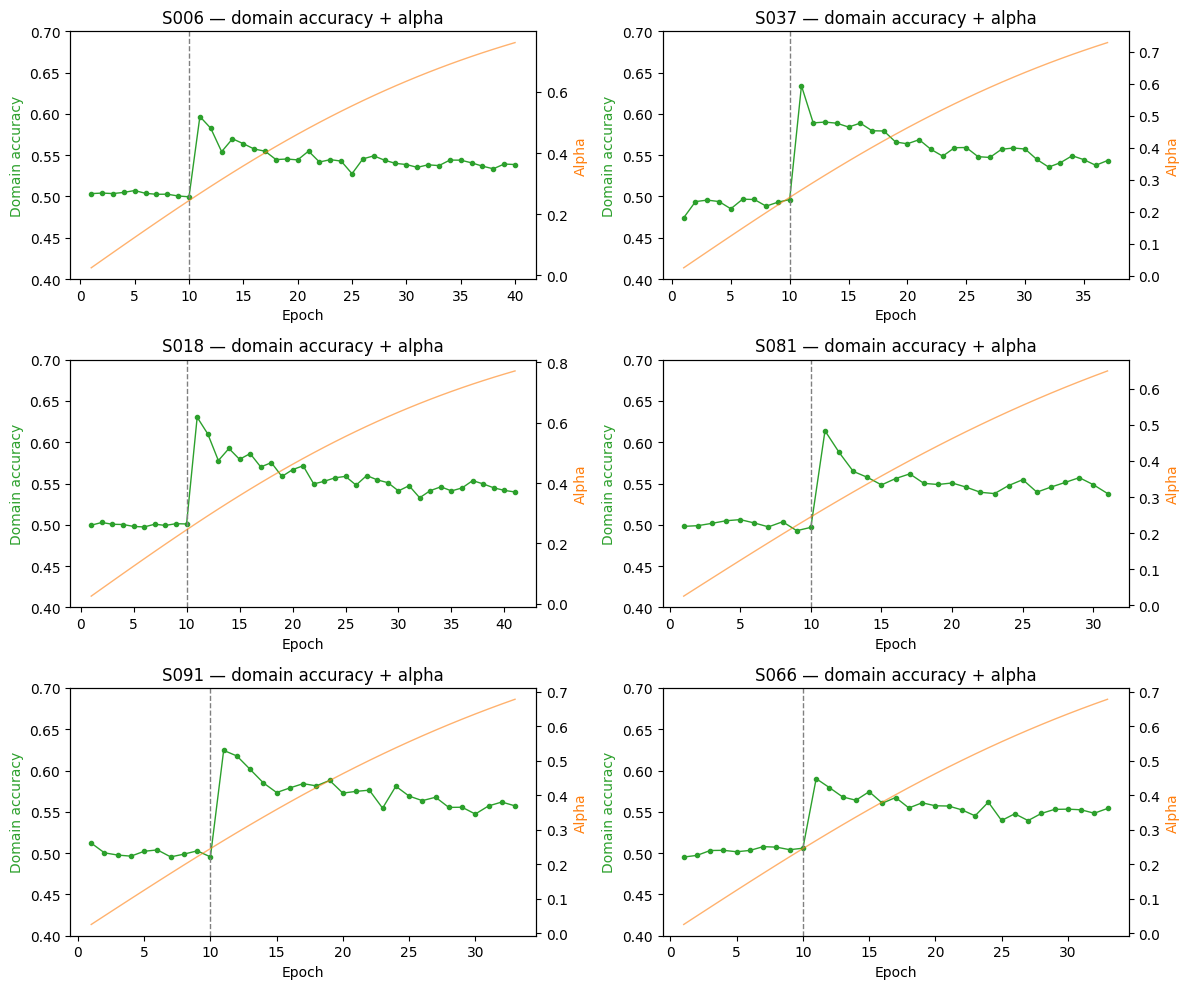

In [122]:
fig, axes = plt.subplots(3, 2, figsize=(12, 10), sharex=False)
axes = axes.flatten()

for ax, subj in zip(axes, subjects_to_plot):
    log = results[subj]['kappa_stopping']['log']
    domain_acc = log['domain_accuracy']
    alpha = log['alpha']
    epochs = list(range(1, len(domain_acc) + 1))

    ax.plot(epochs, domain_acc, marker='o', markersize=3, linewidth=1, color='tab:green', label='domain accuracy')
    ax2 = ax.twinx()
    ax2.plot(epochs, alpha, linewidth=1, color='tab:orange', alpha=0.6, label='alpha (GRL ramp)')
    ax.axvline(x=10, color='gray', linestyle='--', linewidth=1)
    ax.set_title(f"{subj} — domain accuracy + alpha")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Domain accuracy", color='tab:green')
    ax2.set_ylabel("Alpha", color='tab:orange')
    ax.set_ylim(0.4, 0.7)

plt.tight_layout()
plt.savefig('../results/figures/domain_accuracy_alpha_six_subjects.png', dpi=150)
plt.show()

In [120]:
for subj in ['S006', 'S037', 'S018']:
    log = results[subj]['kappa_stopping']['log']
    print(f"{subj}: best_epoch={log['best_epoch']}, total_epochs_run={log['total_epochs_run']}")

S006: best_epoch=7, total_epochs_run=40
S037: best_epoch=1, total_epochs_run=37
S018: best_epoch=1, total_epochs_run=41


### comparison for cdan + multi class 8 channel and multiclass 16 channel

In [123]:
with open(results_path / "loso_results_cdan.json", "r") as f:
    results_binary = json.load(f)

with open(results_path / "loso_results_multiclass_16ch.json", "r") as f:
    results_mc16 = json.load(f)

def summarize(results, label):
    kappa_k = [results[s]['kappa_stopping']['final_kappa'] for s in results if results[s].get('kappa_stopping')]
    kappa_c = [results[s]['composite_stopping']['final_kappa'] for s in results if results[s].get('composite_stopping')]
    print(f"--- {label} ---")
    print(f"n={len(results)} | kappa-stop mean={np.mean(kappa_k):.4f} | composite mean={np.mean(kappa_c):.4f}")
    print(f"above 0.1 (kappa-stop): {sum(k>0.1 for k in kappa_k)}/{len(kappa_k)}")
    print(f"above 0.1 (composite): {sum(k>0.1 for k in kappa_c)}/{len(kappa_c)}")
    print()
    return kappa_k, kappa_c

bin_k, bin_c = summarize(results_binary, "Binary CDAN-8ch")
mc8_k, mc8_c = summarize(results, "Multiclass-8ch")
mc16_k, mc16_c = summarize(results_mc16, "Multiclass-16ch")

--- Binary CDAN-8ch ---
n=106 | kappa-stop mean=0.5180 | composite mean=0.5224
above 0.1 (kappa-stop): 102/106
above 0.1 (composite): 104/106

--- Multiclass-8ch ---
n=106 | kappa-stop mean=0.3182 | composite mean=0.3192
above 0.1 (kappa-stop): 97/106
above 0.1 (composite): 95/106

--- Multiclass-16ch ---
n=106 | kappa-stop mean=0.3382 | composite mean=0.3341
above 0.1 (kappa-stop): 99/106
above 0.1 (composite): 95/106



In [126]:
with open(results_path / "loso_results_16ch.json", "r") as f:
    results_bin16 = json.load(f)

def get_kappas(results, criterion='kappa_stopping'):
    return {s: results[s][criterion]['final_kappa'] for s in results if results[s].get(criterion)}

bin8_k = get_kappas(results_binary)
bin16_k = get_kappas(results_bin16)
mc8_k_d = get_kappas(results)
mc16_k_d = get_kappas(results_mc16)

def delta_report(d8, d16, label):
    common = set(d8) & set(d16)
    deltas = [d16[s] - d8[s] for s in common]
    improved = sum(1 for d in deltas if d > 0)
    print(f"--- {label} ---")
    print(f"8ch mean={np.mean(list(d8.values())):.4f} | 16ch mean={np.mean(list(d16.values())):.4f}")
    print(f"mean delta={np.mean(deltas):+.4f} | improved: {improved}/{len(common)}")
    print()

delta_report(bin8_k, bin16_k, "Binary: 8ch → 16ch")
delta_report(mc8_k_d, mc16_k_d, "Multiclass: 8ch → 16ch")

--- Binary: 8ch → 16ch ---
8ch mean=0.5180 | 16ch mean=0.5387
mean delta=+0.0207 | improved: 57/106

--- Multiclass: 8ch → 16ch ---
8ch mean=0.3182 | 16ch mean=0.3382
mean delta=+0.0200 | improved: 67/106



In [125]:
print(f"Multiclass: 8ch mean={np.mean(mc8_k):.4f} → 16ch mean={np.mean(mc16_k):.4f} | "
      f"delta={np.mean(mc16_k)-np.mean(mc8_k):+.4f}")

n_improved = sum(1 for s in results if s in results_mc16 and
                  results_mc16[s]['kappa_stopping']['final_kappa'] > results[s]['kappa_stopping']['final_kappa'])
print(f"Subjects improved by 16ch (multiclass): {n_improved}/{len(results)}")

Multiclass: 8ch mean=0.3182 → 16ch mean=0.3382 | delta=+0.0200
Subjects improved by 16ch (multiclass): 67/106


### multiclass channel 16 seed 42 

In [127]:
with open(results_path / "loso_results_multiclass_16ch_seed42.json", "r") as f:
    results_mc16_seed42 = load_results("loso_results_multiclass_16ch_seed42.json") if False else json.load(f)

seed1_k = get_kappas(results_mc16)
seed42_k = get_kappas(results_mc16_seed42)

print(f"Seed 1 (original): mean kappa={np.mean(list(seed1_k.values())):.4f}, "
      f"above 0.1: {sum(k>0.1 for k in seed1_k.values())}/{len(seed1_k)}")
print(f"Seed 42: mean kappa={np.mean(list(seed42_k.values())):.4f}, "
      f"above 0.1: {sum(k>0.1 for k in seed42_k.values())}/{len(seed42_k)}")

common = set(seed1_k) & set(seed42_k)
diffs = [seed42_k[s] - seed1_k[s] for s in common]
print(f"Mean per-subject difference between seeds: {np.mean(diffs):+.4f}")
print(f"Std of per-subject difference: {np.std(diffs):.4f}")

Seed 1 (original): mean kappa=0.3382, above 0.1: 99/106
Seed 42: mean kappa=0.3383, above 0.1: 98/106
Mean per-subject difference between seeds: +0.0001
Std of per-subject difference: 0.0534


### Multiclass 16 chann + baseline deep dive

#### Q1
-Q1 (does DA work): the headline table — mean kappa, above-threshold count, for all four configs. 

In [128]:

results_path = Path("../results")

def load_results(filename):
    with open(results_path / filename, "r") as f:
        return json.load(f)

results_bin8 = load_results("loso_results_cdan.json")
results_bin16 = load_results("loso_results_16ch.json")
results_mc8 = load_results("loso_results_multiclass.json")
results_mc16 = load_results("loso_results_multiclass_16ch.json")

ALL_RESULTS = {
    "binary_8ch": results_bin8,
    "binary_16ch": results_bin16,
    "multiclass_8ch": results_mc8,
    "multiclass_16ch": results_mc16,
}

def get_kappas(results, criterion='kappa_stopping'):
    return {s: results[s][criterion]['final_kappa'] for s in results if results[s].get(criterion)}

def get_per_class_accuracy(results, subject_id, criterion='kappa_stopping'):
    log = results[subject_id][criterion]['log']
    pca = log.get('final_per_class_accuracy')
    if pca is None:
        return None
    return {int(k): v for k, v in pca.items()}

def get_confusion_matrix(results, subject_id, criterion='kappa_stopping'):
    log = results[subject_id][criterion]['log']
    cm = log.get('final_confusion_matrix')
    return np.array(cm) if cm is not None else None

print("Loaded:", {k: len(v) for k, v in ALL_RESULTS.items()})

Loaded: {'binary_8ch': 106, 'binary_16ch': 106, 'multiclass_8ch': 106, 'multiclass_16ch': 106}


In [136]:
summary_rows = []
for label, results in ALL_RESULTS.items():
    for criterion in ['kappa_stopping', 'composite_stopping']:
        kappas = get_kappas(results, criterion)
        vals = list(kappas.values())
        summary_rows.append({
            'config': label, 'criterion': criterion,
            'mean': np.mean(vals), 'median': np.median(vals), 'std': np.std(vals),
            'above_0.1': sum(k > 0.1 for k in vals), 'n': len(vals)
        })

q1_df = pd.DataFrame(summary_rows)
print(q1_df.round(4))

            config           criterion    mean  median     std  above_0.1    n
0       binary_8ch      kappa_stopping  0.5180  0.4990  0.2311        102  106
1       binary_8ch  composite_stopping  0.5224  0.5023  0.2295        104  106
2      binary_16ch      kappa_stopping  0.5387  0.5450  0.2416        102  106
3      binary_16ch  composite_stopping  0.5366  0.5429  0.2329        103  106
4   multiclass_8ch      kappa_stopping  0.3182  0.2832  0.1946         97  106
5   multiclass_8ch  composite_stopping  0.3192  0.2912  0.1871         95  106
6  multiclass_16ch      kappa_stopping  0.3382  0.3133  0.1901         99  106
7  multiclass_16ch  composite_stopping  0.3341  0.3222  0.2030         95  106
8        gp_warmup      kappa_stopping  0.5154  0.5052  0.2235        105  106
9        gp_warmup  composite_stopping  0.5070  0.5020  0.2363        103  106


#### Q2
-Q2 (does 16ch help): the delta comparison — same effect size in both tasks (~+0.02), similar proportion of subjects improved 

In [131]:
def delta_report(d8, d16):
    common = set(d8) & set(d16)
    deltas = [d16[s] - d8[s] for s in common]
    return {
        'mean_8ch': np.mean(list(d8.values())),
        'mean_16ch': np.mean(list(d16.values())),
        'mean_delta': np.mean(deltas),
        'improved': sum(d > 0 for d in deltas),
        'n': len(common)
    }

print("Binary:", delta_report(get_kappas(results_bin8), get_kappas(results_bin16)))
print("Multiclass:", delta_report(get_kappas(results_mc8), get_kappas(results_mc16)))

Binary: {'mean_8ch': np.float64(0.5180363729177594), 'mean_16ch': np.float64(0.5387250313015807), 'mean_delta': np.float64(0.02068865838382134), 'improved': 57, 'n': 106}
Multiclass: {'mean_8ch': np.float64(0.31821194171040024), 'mean_16ch': np.float64(0.3382489491852092), 'mean_delta': np.float64(0.02003700747480891), 'improved': 67, 'n': 106}


#### Q3
-Q3 (where does it fail): below-threshold subject lists + the confusion matrix pattern (left/right leaking into both-fists, not into each other)

In [139]:
def below_threshold(results, threshold=0.1):
    kappa_list = sorted([s for s, k in get_kappas(results, 'kappa_stopping').items() if k <= threshold])
    composite_list = sorted([s for s, k in get_kappas(results, 'composite_stopping').items() if k <= threshold])
    return {'kappa_stopping': kappa_list, 'composite_stopping': composite_list}

mc8_below = below_threshold(results_mc8)
print("Multiclass-8ch below 0.1:")
print("  kappa-stopping:", mc8_below['kappa_stopping'])
print("  composite-stopping:", mc8_below['composite_stopping'])

mc16_below = below_threshold(results_mc16)
print("\nMulticlass-16ch below 0.1:")
print("  kappa-stopping:", mc16_below['kappa_stopping'])
print("  composite-stopping:", mc16_below['composite_stopping'])

bin8_below = below_threshold(results_bin8)
print("\nCDAN-8ch below 0.1:")
print("  kappa-stopping:", bin8_below['kappa_stopping'])
print("  composite-stopping:", bin8_below['composite_stopping'])

bin16_below = below_threshold(results_bin16)
print("\nCDAN-16ch below 0.1:")
print("  kappa-stopping:", bin16_below['kappa_stopping'])
print("  composite-stopping:", bin16_below['composite_stopping'])

# gp_below = below_threshold(results_gp_warmup)
# print("\nGP+warmup-8ch below 0.1:")
# print("  kappa-stopping:", gp_below['kappa_stopping'])
# print("  composite-stopping:", gp_below['composite_stopping'])

Multiclass-8ch below 0.1:
  kappa-stopping: ['S006', 'S009', 'S018', 'S020', 'S037', 'S039', 'S067', 'S097', 'S107']
  composite-stopping: ['S003', 'S006', 'S018', 'S020', 'S039', 'S053', 'S067', 'S097', 'S099', 'S107', 'S109']

Multiclass-16ch below 0.1:
  kappa-stopping: ['S003', 'S009', 'S018', 'S039', 'S051', 'S074', 'S076']
  composite-stopping: ['S006', 'S009', 'S017', 'S018', 'S038', 'S039', 'S040', 'S063', 'S067', 'S090', 'S109']

CDAN-8ch below 0.1:
  kappa-stopping: ['S003', 'S006', 'S018', 'S020']
  composite-stopping: ['S003', 'S018']

CDAN-16ch below 0.1:
  kappa-stopping: ['S003', 'S006', 'S018', 'S037']
  composite-stopping: ['S003', 'S018', 'S053']


In [141]:
all_lists = {
    'mc8_kappa': ['S006','S009','S018','S020','S037','S039','S067','S097','S107'],
    'mc8_composite': ['S003','S006','S018','S020','S039','S053','S067','S097','S099','S107','S109'],
    'mc16_kappa': ['S003','S009','S018','S039','S051','S074','S076'],
    'mc16_composite': ['S006','S009','S017','S018','S038','S039','S040','S063','S067','S090','S109'],
    'bin8_kappa': ['S003','S006','S018','S020'],
    'bin8_composite': ['S003','S018'],
    'bin16_kappa': ['S003','S006','S018','S037'],
    'bin16_composite': ['S003','S018','S053'],
}

from collections import Counter
counts = Counter()
for lst in all_lists.values():
    counts.update(lst)

for subj, n in counts.most_common():
    where = [name for name, lst in all_lists.items() if subj in lst]
    print(f"{subj}: appears in {n}/8 lists -> {where}")

S018: appears in 8/8 lists -> ['mc8_kappa', 'mc8_composite', 'mc16_kappa', 'mc16_composite', 'bin8_kappa', 'bin8_composite', 'bin16_kappa', 'bin16_composite']
S003: appears in 6/8 lists -> ['mc8_composite', 'mc16_kappa', 'bin8_kappa', 'bin8_composite', 'bin16_kappa', 'bin16_composite']
S006: appears in 5/8 lists -> ['mc8_kappa', 'mc8_composite', 'mc16_composite', 'bin8_kappa', 'bin16_kappa']
S039: appears in 4/8 lists -> ['mc8_kappa', 'mc8_composite', 'mc16_kappa', 'mc16_composite']
S009: appears in 3/8 lists -> ['mc8_kappa', 'mc16_kappa', 'mc16_composite']
S020: appears in 3/8 lists -> ['mc8_kappa', 'mc8_composite', 'bin8_kappa']
S067: appears in 3/8 lists -> ['mc8_kappa', 'mc8_composite', 'mc16_composite']
S037: appears in 2/8 lists -> ['mc8_kappa', 'bin16_kappa']
S097: appears in 2/8 lists -> ['mc8_kappa', 'mc8_composite']
S107: appears in 2/8 lists -> ['mc8_kappa', 'mc8_composite']
S053: appears in 2/8 lists -> ['mc8_composite', 'bin16_composite']
S109: appears in 2/8 lists -> ['mc

In [143]:
from collections import Counter

# build below-threshold lists directly from results, not from memory
all_configs = {
    'mc8_kappa': get_kappas(results_mc8, 'kappa_stopping'),
    'mc8_composite': get_kappas(results_mc8, 'composite_stopping'),
    'mc16_kappa': get_kappas(results_mc16, 'kappa_stopping'),
    'mc16_composite': get_kappas(results_mc16, 'composite_stopping'),
    'bin8_kappa': get_kappas(results_bin8, 'kappa_stopping'),
    'bin8_composite': get_kappas(results_bin8, 'composite_stopping'),
    'bin16_kappa': get_kappas(results_bin16, 'kappa_stopping'),
    'bin16_composite': get_kappas(results_bin16, 'composite_stopping'),
}

below_lists = {name: [s for s, k in kappas.items() if k <= 0.1] for name, kappas in all_configs.items()}

counts = Counter()
for lst in below_lists.values():
    counts.update(lst)

max_count = max(counts.values())
most_consistent_failures = [s for s, n in counts.items() if n == max_count]
print(f"Subject(s) failing in the most configs ({max_count}/8 tested): {most_consistent_failures}")
for subj in most_consistent_failures:
    where = [name for name, lst in below_lists.items() if subj in lst]
    print(f"  {subj} fails in: {where}")

print()

# classify multiclass-8ch failures into the two patterns, derived from per-class accuracy
mc8_failures = below_lists['mc8_kappa']
group_a, group_b = [], []

for subj in mc8_failures:
    pca = get_per_class_accuracy(results_mc8, subj, 'kappa_stopping')
    accs = list(pca.values())
    min_acc = min(accs)
    other_accs = [a for a in accs if a != min_acc]
    weakest_class = [c for c, a in pca.items() if a == min_acc][0]

    # Group A: one class collapses near-zero while others remain reasonably present
    # Group B: everything flat and near chance (0.25), no class stands out as collapsed
    if min_acc < 0.10 and max(other_accs) > 0.35:
        group_a.append((subj, weakest_class, pca))
    else:
        group_b.append((subj, pca))

class_names = {0: 'left', 1: 'right', 2: 'both-fists', 3: 'both-feet'}

print("Group A (selective single-class collapse):")
for subj, weak_class, pca in group_a:
    print(f"  {subj}: collapsed class = {class_names[weak_class]} | full breakdown: "
          f"{ {class_names[k]: round(v,2) for k,v in pca.items()} }")

print("\nGroup B (flat, near-chance across all classes):")
for subj, pca in group_b:
    print(f"  {subj}: full breakdown: { {class_names[k]: round(v,2) for k,v in pca.items()} }")

Subject(s) failing in the most configs (8/8 tested): ['S018']
  S018 fails in: ['mc8_kappa', 'mc8_composite', 'mc16_kappa', 'mc16_composite', 'bin8_kappa', 'bin8_composite', 'bin16_kappa', 'bin16_composite']

Group A (selective single-class collapse):
  S006: collapsed class = right | full breakdown: {'left': 0.21, 'right': 0.05, 'both-fists': 0.59, 'both-feet': 0.43}
  S018: collapsed class = right | full breakdown: {'left': 0.41, 'right': 0.0, 'both-fists': 0.45, 'both-feet': 0.3}
  S037: collapsed class = right | full breakdown: {'left': 0.43, 'right': 0.0, 'both-fists': 0.77, 'both-feet': 0.05}

Group B (flat, near-chance across all classes):
  S009: full breakdown: {'left': 0.33, 'right': 0.29, 'both-fists': 0.3, 'both-feet': 0.18}
  S020: full breakdown: {'left': 0.39, 'right': 0.2, 'both-fists': 0.27, 'both-feet': 0.38}
  S039: full breakdown: {'left': 0.35, 'right': 0.14, 'both-fists': 0.35, 'both-feet': 0.41}
  S067: full breakdown: {'left': 0.32, 'right': 0.22, 'both-fists': 

In [140]:
def get_agg_confusion(results, criterion='kappa_stopping', n_classes=2):
    agg = np.zeros((n_classes, n_classes))
    for subject_id in results:
        cm = get_confusion_matrix(results, subject_id, criterion)
        if cm is not None:
            agg += cm
    return agg

# multiclass-8ch
class_names = ['left', 'right', 'both-fists', 'both-feet']
for criterion in ['kappa_stopping', 'composite_stopping']:
    agg_cm = get_agg_confusion(results_mc8, criterion, n_classes=4)
    row_norm = agg_cm / agg_cm.sum(axis=1, keepdims=True)
    print(f"\nMulticlass-8ch row-normalized confusion matrix ({criterion}):")
    print(pd.DataFrame(row_norm, index=class_names, columns=class_names).round(3))

# multiclass-16ch
for criterion in ['kappa_stopping', 'composite_stopping']:
    agg_cm = get_agg_confusion(results_mc16, criterion, n_classes=4)
    row_norm = agg_cm / agg_cm.sum(axis=1, keepdims=True)
    print(f"\nMulticlass-16ch row-normalized confusion matrix ({criterion}):")
    print(pd.DataFrame(row_norm, index=class_names, columns=class_names).round(3))


Multiclass-8ch row-normalized confusion matrix (kappa_stopping):
             left  right  both-fists  both-feet
left        0.517  0.121       0.212      0.149
right       0.155  0.459       0.232      0.155
both-fists  0.209  0.171       0.479      0.141
both-feet   0.185  0.172       0.146      0.497

Multiclass-8ch row-normalized confusion matrix (composite_stopping):
             left  right  both-fists  both-feet
left        0.525  0.117       0.219      0.139
right       0.157  0.471       0.228      0.144
both-fists  0.202  0.194       0.460      0.143
both-feet   0.191  0.166       0.141      0.502

Multiclass-16ch row-normalized confusion matrix (kappa_stopping):
             left  right  both-fists  both-feet
left        0.558  0.109       0.191      0.142
right       0.164  0.467       0.211      0.158
both-fists  0.217  0.175       0.467      0.141
both-feet   0.206  0.142       0.131      0.521

Multiclass-16ch row-normalized confusion matrix (composite_stopping):
      

Multiclass-8ch has 9 subjects below the 0.1 kappa threshold; multiclass-16ch has 7. But it's not the same 7 — only 3 subjects (S009, S018, S039) fail in both. 16ch resolves most of the 8ch failures but introduces a handful of new ones. 

The confusion matrix shows the failure isn't really a left/right mixup, left and right are rarely confused with each other (12%, 16%); the bigger leak is both binary classes being misclassified as both-fists more than as each other. 

This points to a binary-class-vs-bilateral-movement confusion as the dominant error pattern

#### Q4
-Q4 (failure mode characterization)

In [134]:
# new 16ch-only failures: were they fine at 8ch, and what does their failure look like at 16ch?
new_16ch_failures = ['S003', 'S051', 'S074', 'S076']

print("--- New 16ch failures: per-class accuracy at 16ch, plus their 8ch kappa for comparison ---\n")
for subj in new_16ch_failures:
    pca_16 = get_per_class_accuracy(results_mc16, subj, 'kappa_stopping')
    kappa_8 = results_mc8[subj]['kappa_stopping']['final_kappa']
    kappa_16 = results_mc16[subj]['kappa_stopping']['final_kappa']
    print(f"{subj}: 8ch kappa={kappa_8:.3f} -> 16ch kappa={kappa_16:.3f} | "
          f"16ch per-class: left={pca_16[0]:.2f} right={pca_16[1]:.2f} "
          f"both-fists={pca_16[2]:.2f} both-feet={pca_16[3]:.2f}")

print("\n--- S037 specifically: did 'right' actually recover at 16ch? ---\n")
for label, results in [('8ch', results_mc8), ('16ch', results_mc16)]:
    pca = get_per_class_accuracy(results, 'S037', 'kappa_stopping')
    kappa = results['S037']['kappa_stopping']['final_kappa']
    print(f"S037 {label}: kappa={kappa:.3f} | left={pca[0]:.2f} right={pca[1]:.2f} "
          f"both-fists={pca[2]:.2f} both-feet={pca[3]:.2f}")

--- New 16ch failures: per-class accuracy at 16ch, plus their 8ch kappa for comparison ---

S003: 8ch kappa=0.116 -> 16ch kappa=0.089 | 16ch per-class: left=0.09 right=0.29 both-fists=0.43 both-feet=0.46
S051: 8ch kappa=0.140 -> 16ch kappa=0.094 | 16ch per-class: left=0.33 right=0.45 both-fists=0.00 both-feet=0.46
S074: 8ch kappa=0.104 -> 16ch kappa=0.070 | 16ch per-class: left=0.62 right=0.10 both-fists=0.23 both-feet=0.23
S076: 8ch kappa=0.126 -> 16ch kappa=0.090 | 16ch per-class: left=0.30 right=0.48 both-fists=0.22 both-feet=0.27

--- S037 specifically: did 'right' actually recover at 16ch? ---

S037 8ch: kappa=0.086 | left=0.43 right=0.00 both-fists=0.77 both-feet=0.05
S037 16ch: kappa=0.130 | left=0.78 right=0.05 both-fists=0.32 both-feet=0.24


Multiclass failures split into two types, not one. Six subjects (S009, S020, S039, S067, S097, S107) show flat, near-chance performance across all four classes mostly general weak signal. 

Three subjects (S006, S037, S018) perform fine on three classes but the model almost never predicts 'right hand' for them specifically. Checked not caused by adversarial training, present from epoch 1, before adversarial training even starts. 

Separately, aggregate kappa crossing the 0.1 threshold doesn't always mean the actual problem resolved S037 clears the threshold at 16ch, but its right-class accuracy is still 0 either way; the improvement came from other classes, not a real fix.

In [135]:
# Looking inside the multiclass failures (kappa-stopping, 8ch) reveals two distinct patterns, not one uniform 'weak signal' story. Six subjects (S009, S020, S039, S067, S097, S107) are flat and near-chance across all four classes — consistent with the broader literature on weak motor-imagery signal in some individuals. Three subjects (S006, S037, S018) are different: they perform reasonably on three of the four classes but the model almost never predicts 'right hand' for them — not confused with another class, simply absent as a prediction. Checking training dynamics confirms this isn't caused by the adversarial training process: domain accuracy curves for these three look identical to subjects with no problem at all, and the right-class collapse is present from epoch 1, before adversarial training even activates.
# A related finding from comparing 8ch and 16ch: the aggregate kappa improving for a subject doesn't always mean their specific problem resolved. S037 crosses the 0.1 threshold at 16ch (0.086 → 0.130), but right-class accuracy is unchanged (0.00 → 0.05) — the improvement came entirely from other classes, not from fixing the actual failure. This means a subject's pass/fail status against a single aggregate threshold can mask whether the underlying transfer problem was actually addressed — exactly the kind of distinction this thesis's XAI phase is meant to investigate

#### gp warm up and cdann check

In [130]:
results_gp_warmup = load_results("loso_results_gp_warmup.json")
ALL_RESULTS["gp_warmup"] = results_gp_warmup

for criterion in ['kappa_stopping', 'composite_stopping']:
    kappas = get_kappas(results_gp_warmup, criterion)
    vals = list(kappas.values())
    print(f"GP+warmup, {criterion}: mean={np.mean(vals):.4f}, median={np.median(vals):.4f}, "
          f"std={np.std(vals):.4f}, above_0.1={sum(k>0.1 for k in vals)}/106")

for criterion in ['kappa_stopping', 'composite_stopping']:
    kappas = get_kappas(results_bin8, criterion)
    vals = list(kappas.values())
    print(f"CDAN-8ch, {criterion}: mean={np.mean(vals):.4f}, median={np.median(vals):.4f}, "
          f"std={np.std(vals):.4f}, above_0.1={sum(k>0.1 for k in vals)}/106")

GP+warmup, kappa_stopping: mean=0.5154, median=0.5052, std=0.2235, above_0.1=105/106
GP+warmup, composite_stopping: mean=0.5070, median=0.5020, std=0.2363, above_0.1=103/106
CDAN-8ch, kappa_stopping: mean=0.5180, median=0.4990, std=0.2311, above_0.1=102/106
CDAN-8ch, composite_stopping: mean=0.5224, median=0.5023, std=0.2295, above_0.1=104/106


### GP Warmup on 16 channel

In [1]:
import json
import numpy as np
import pandas as pd
from pathlib import Path

results_path = Path("../results")

def load_results(filename):
    with open(results_path / filename, "r") as f:
        return json.load(f)

results_bin16 = load_results("loso_results_16ch.json")
results_gp16 = load_results("loso_results_gp_warmup_16ch.json")

def get_kappas(results, criterion='kappa_stopping'):
    return {s: results[s][criterion]['final_kappa'] for s in results if results[s].get(criterion)}

print("Loaded:", {"CDAN-16ch": len(results_bin16), "GP+warmup-16ch": len(results_gp16)})

Loaded: {'CDAN-16ch': 106, 'GP+warmup-16ch': 106}


In [2]:
for label, results in [("CDAN-16ch", results_bin16), ("GP+warmup-16ch", results_gp16)]:
    for criterion in ['kappa_stopping', 'composite_stopping']:
        vals = list(get_kappas(results, criterion).values())
        print(f"{label}, {criterion}: mean={np.mean(vals):.4f}, median={np.median(vals):.4f}, "
              f"std={np.std(vals):.4f}, above_0.1={sum(v>0.1 for v in vals)}/106")

CDAN-16ch, kappa_stopping: mean=0.5387, median=0.5450, std=0.2416, above_0.1=102/106
CDAN-16ch, composite_stopping: mean=0.5366, median=0.5429, std=0.2329, above_0.1=103/106
GP+warmup-16ch, kappa_stopping: mean=0.5318, median=0.5297, std=0.2459, above_0.1=103/106
GP+warmup-16ch, composite_stopping: mean=0.5359, median=0.5183, std=0.2364, above_0.1=104/106


In [3]:
with open('../functions/pipeline.py', 'r') as f:
    content = f.read()

print("torch.save" in content)

False
